In [1]:
from polair import _helpers as h
from polair import _calibration as calibration 
from polair import _corr_fcts as corr
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
import yaml
import subprocess
import glob
import os
from scipy import signal
from scipy.signal import hilbert, find_peaks

In [2]:
campaign_dir = "/Users/lakoeh001/AWI/Programmierung/sanat_processing/"
plot_dir = "/Users/lakoeh001/AWINextcloud/personal/lakoeh001/aircrafts/Formelsammlung/"

# SANAT: Manual processing steps

Not all steps of the turbulence processing can be automated. The definition segment times and the calibration has to be done manually. Here is the code which can be used for this. It uses the calibrated raw data of a flight. Restart kernel when changing flight.

## Find corrupted lines

If the preprocessing doesn't work, the downloaded files are sometimes corrupted. To find the corrupted lines and remove them from the files, here are some things you can try.

In [6]:
fn = "/Users/lakoeh001/AWI/Campaigns/20260103SANAT/Daten/RF10_20260129/20260129_RF10/20260129_P6_RF10_GPS1.ATEL.dat"

In [7]:
with open(fn, "rb") as f:
    for i, line in enumerate(f, start=1):
        try:
            line.decode("utf-8")
        except UnicodeDecodeError as e:
            print(f"Unicode error in line {i}: {e}")
            print(line[:200])  # show beginning of bad line
            break


In [14]:
3881 * 2 # If the file has an empty line between every timestep, we have to double the line number since the empty lines are not imported

7762

In [111]:
# Broken indices can lead to errors.

df = pd.read_csv(fn, header  = 4, sep = r'\s+', names = ["date", "time", f"var"])
#df = h.get_timestamps(df)

In [112]:
bad_idx = [i for i, x in enumerate(df["time"]) if len(str(x)) != 15]

In [113]:
bad_idx

[]

In [116]:
# Dublicated time stamps can also lead to errors

dup_times = df.loc[df["time"].duplicated(), "time"]
dup_times

713462    19:36:42.721124
713473    19:36:45.070794
Name: time, dtype: object

df = df[df[v].str.startswith("$GPGGA")].reset_index()

ValueError: Cannot mask with non-boolean array containing NA / NaN values

In [ ]:
bad = gpgga[
    gpgga[v].str.len() < 60
]

bad

## Import the data

In [4]:
flight = 9
config_file = f"{campaign_dir}/config_sanat.yaml"

In [17]:
config = h.import_dictionary(config_file)
logfile = h.create_logfile(config)
vars = h.import_dictionary(config["paths"]["variables"])
out_vars = h.import_dictionary(config["paths"]["processed_variables"])
fhp_params = h.import_dictionary(config["paths"]["fiveholeprobe"])
outdir_raw = config["paths"]["outdirs"]["raw"]
outdir_nb = config["paths"]["outdirs"]["noseboom"]
flight_date = str(config["flights"][flight]["date"]).replace("-","")
campaign = config["campaign"]["name"]
fn_in = outdir_raw+"/"+campaign+"_"+flight_date+f"_RF{flight:02}_calibrated_raw_data.nc"
fn_out = outdir_nb+"/"+campaign+"_"+flight_date+f"_RF{flight:02}_noseboom_100Hz.nc"

data = xr.open_dataset(fn_in)

## Get start and stop

Determine start and stop time for time integration of INS and the data range provided in the final files.

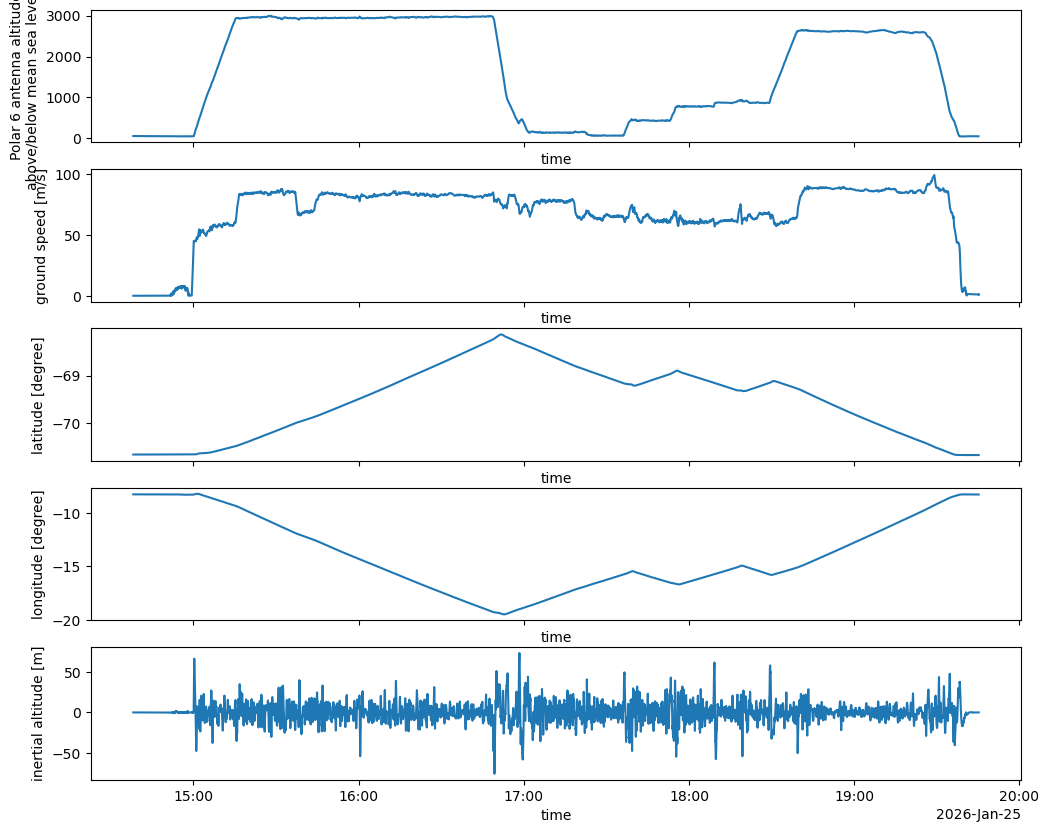

In [72]:
start = np.datetime64("2024-04-29T10:28:00")
stop = np.datetime64("2024-04-29T13:18:30")

# usefule variables: gs,h_ins, lat, lon, h_gpgga

#data.gs.plot()
fig, axs = plt.subplots(5,1,figsize=(12,10),sharex=True)

for v, ax in zip(["h_gpgga", "gs", "lat", "lon", "h"], fig.get_axes()):
    data[v].plot(ax = ax)
#    ax.axvline(start, c = "tab:red")
#    ax.axvline(stop, c = "tab:red")

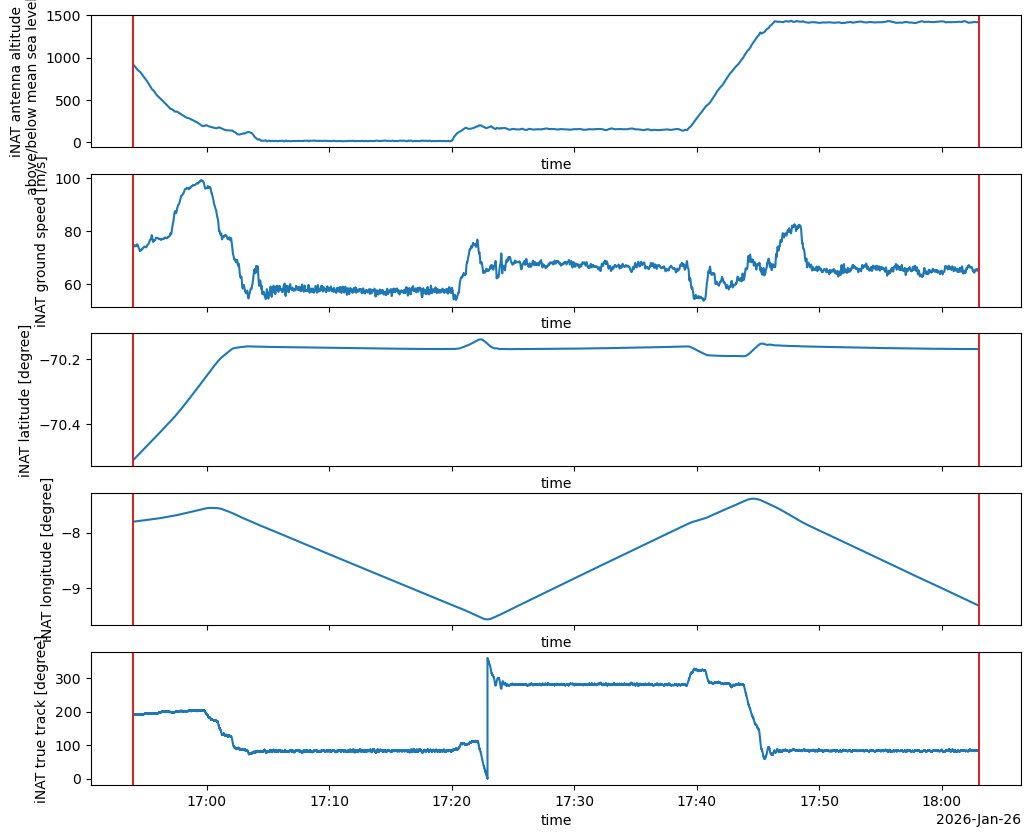

In [91]:
# For T-Bird

start = np.datetime64("2026-01-26T16:54:00")
stop = np.datetime64("2026-01-26T18:03:00")

# usefule variables: gs_inat, h_inat, lat_inat, lon_inat

#data.gs.plot()
fig, axs = plt.subplots(5,1,figsize=(12,10),sharex=True)

for v, ax in zip(["h_inat", "gs_inat", "lat_inat", "lon_inat", "ttrk_inat"], fig.get_axes()):
    data[v].sel(time = slice(start,stop)).plot(ax = ax)
#    data[v].plot(ax = ax)
    ax.axvline(start, c = "tab:red")
    ax.axvline(stop, c = "tab:red")

#fig.savefig("/Users/lakoeh001/Desktop/tbird_gps_20240410.pdf")

## Get segments

Each flight is divided into segments to make it easier to work with the data.

In [6]:
# Calculate parameters useful for segment determination

start = config["flights"][flight]["start"]
stop = config["flights"][flight]["stop"]

pf = "noseboom"
twist_angle = np.deg2rad(config["campaign"]["noseboom_twist"])

for v in ["qb", "qc", "ps", "alpha", "beta"]:
    da = corr.alignement_correction(data, fhp_params, v, pf, twist_angle).rename(v)
    try:
        data_corr[v] = da
    except:
        data_corr = da.to_dataset()

# Some corrections:
data_corr["qc"] = data_corr["qc"].where(data_corr["qc"]>0, other = 0)
data_corr["alpha"] = data_corr["alpha"].where(data_corr["qc"]>500, other = 0)
data_corr["beta"] = data_corr["beta"].where(data_corr["qc"]>500, other = 0)

# adiabatic corrections for sensors in Rosemount/Goodrich housings
etaE = 1.00025  # recovery factor for deiced sensors
for temp in ["TejB", "ThuB", "Te_N", "ThuN", "TejN"]:
    name = f"{temp}_corr"
    if temp == "TejB":
        da = corr.sat_correction(data, data_corr, temp, recovery=etaE).rename(name)
    else:
        da = corr.sat_correction(data, data_corr, temp).rename(name)
    try:
        data_corr[name] = da
    except:
        data_corr = da.to_dataset()

# Correct relative humidity using the Magnus formula for the saturation pressure.
rh_corr = corr.humidity_correction(data.rFHuN, data.ThuN, data_corr.Te_N_corr)
data_corr["rFHuN_corr"] = rh_corr

# Correction of INS with GPS
w_ins = corr.get_w_ins(data, start, stop)
h_ins = corr.get_h_ins(w_ins["w_ins"])
data = xr.merge([data, w_ins, h_ins])

for v in ["lat", "lon", "gs", "h_ins", "w_ins", "vew", "vns"]:
    gps_corr = corr.correct_ins_with_gps(data, v)
    data_corr = xr.merge([data_corr, gps_corr])

ttrk_corr = corr.correct_ttrk_ins_with_gps(data, data_corr, "ttrk")
data_corr = xr.merge([data_corr, ttrk_corr])

# Calculate true airspeed
data_corr["tas"] = corr.get_true_air_speed(data_corr, pf)

for v in ["u", "v", "vertwind"]:
    wind_comp = corr.get_wind_component(data, data_corr, v, pf)
    data_corr[v] = wind_comp

In [18]:
cal_segs = config["flights"][flight]["calibration"]

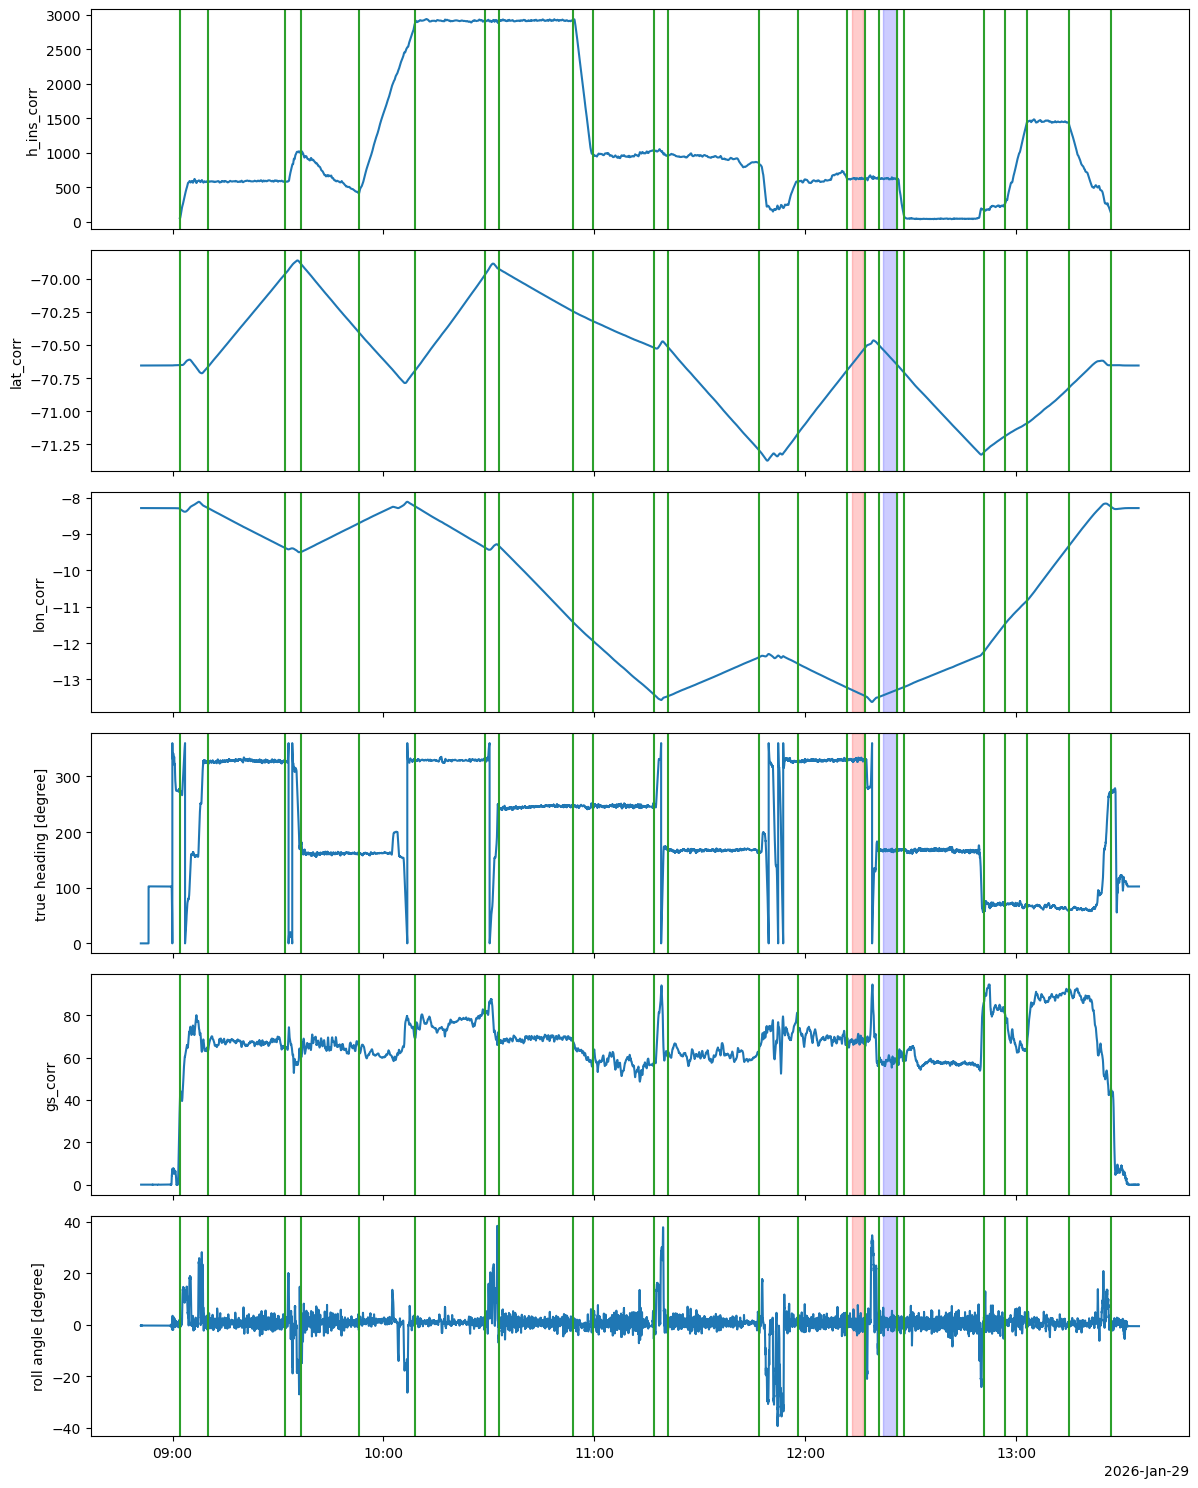

In [19]:
fig, axs = plt.subplots(6,1,figsize=(12,15),sharex=True)

data_corr.h_ins_corr.plot(ax = axs[0])
data_corr.lat_corr.plot(ax = axs[1])
data_corr.lon_corr.plot(ax = axs[2])
data.thdg.plot(ax = axs[3])
data_corr.gs_corr.plot(ax = axs[4])
data["roll"].plot(ax = axs[5])

seglist = []

#calsegs = ["2026-01-21T13:04:00", "2026-01-21T13:13:00",
#           "2026-01-21T13:19:00", "2026-01-21T13:26:00"]
calsegs = []

# If segments are aleady determined, it is possible to plot them here with the switch:
if 1:
    try:
        seg_fn = config["paths"]["segments"]
        segments = h.import_dictionary(seg_fn)
        flight_segments = segments["flights"][flight]["segments"]
        for i in np.arange(len(flight_segments)):
            t = flight_segments[i]['time']
            seglist.append(t)
    except:
        print("No segment file available")

seglist = np.array(seglist).astype("datetime64")
calsegs = np.array(calsegs).astype("datetime64")

for ax in fig.get_axes():
    ax.set_xlabel("")
    for s in seglist:
        ax.axvline(s, color = "tab:green")
    for cal in calsegs:
        ax.axvline(cal, color = "tab:red")

# If calibration segments are already available:
for ax in fig.get_axes():
    for key, val in cal_segs.items():
        start = val['start']
        stop = val['stop']
        
        # optional: different colors for "out" vs "ret"
        color = 'red' if 'out' in key else 'blue'
        
        ax.axvspan(start, stop, alpha=0.2, color=color)

plt.tight_layout()

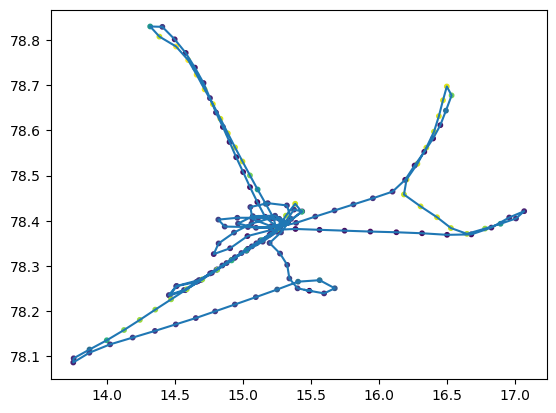

In [197]:
# The flight track might also be useful for the segemnts:
min = data_corr.resample(time = "1min").mean()

plt.plot(min.lon_corr, min.lat_corr)
plt.scatter(min.lon_corr, min.lat_corr, c=min.h_ins_corr.values, s=10, cmap="viridis")

#### Adjusting calibration segments:

Calibration segments are mainly identified looking at the segmentation above and from the flight reports where it is indicated when they were flown. However, they need to be adjusted to have the same length, i.e. same start and end point.

In [9]:
cal_segs

{'out1': {'start': datetime.datetime(2026, 1, 29, 12, 12),
  'stop': datetime.datetime(2026, 1, 29, 12, 17)},
 'ret1': {'start': datetime.datetime(2026, 1, 29, 12, 21),
  'stop': datetime.datetime(2026, 1, 29, 12, 26)}}

In [20]:
calnum = 1
out = data_corr.sel(time = slice(cal_segs[f"out{calnum}"]["start"],cal_segs[f"out{calnum}"]["stop"]))
ret = data_corr.sel(time = slice(cal_segs[f"ret{calnum}"]["start"],cal_segs[f"ret{calnum}"]["stop"]))

In [16]:
import numpy as np
from scipy.spatial import cKDTree

def latlon_to_xyz(lat, lon, R=6371000.0):
    lat_r = np.radians(lat)
    lon_r = np.radians(lon)
    x = R * np.cos(lat_r) * np.cos(lon_r)
    y = R * np.cos(lat_r) * np.sin(lon_r)
    z = R * np.sin(lat_r)
    return np.column_stack([x, y, z])

xyz_out = latlon_to_xyz(out.lat_corr.values, out.lon_corr.values)
xyz_ret = latlon_to_xyz(ret.lat_corr.values, ret.lon_corr.values)

# 1. Bogenlänge entlang von "out" als gemeinsames Lineal
seg_len = np.linalg.norm(np.diff(xyz_out, axis=0), axis=1)
s_out = np.concatenate([[0], np.cumsum(seg_len)])  # Meter entlang des out-Tracks

# 2. ret-Punkte auf den out-Track projizieren (nearest neighbor)
tree_out = cKDTree(xyz_out)
dist_ret, idx_ret = tree_out.query(xyz_ret)   # idx_ret zeigt auf Position in out

threshold_m = 60
mask_ret = dist_ret < threshold_m

s_ret = s_out[idx_ret]   # ret-Punkte jetzt im selben "s"-Koordinatensystem wie out

# 3. Überlappungsbereich in s bestimmen (nur gültige, nahe Punkte berücksichtigen)
s_out_valid = s_out          # out hat s per Definition komplett
s_ret_valid = s_ret[mask_ret]

s_min = max(s_out_valid.min(), s_ret_valid.min())
s_max = min(s_out_valid.max(), s_ret_valid.max())

# 4. Zeiten rausholen: wo liegt jeder Track im überlappenden s-Bereich?
mask_out_overlap = (s_out >= s_min) & (s_out <= s_max)
mask_ret_overlap = mask_ret & (s_ret >= s_min) & (s_ret <= s_max)

start_out = out.time.values[mask_out_overlap][0]
stop_out  = out.time.values[mask_out_overlap][-1]

start_ret = ret.time.values[mask_ret_overlap][0]
stop_ret  = ret.time.values[mask_ret_overlap][-1]

print("out overlap:", start_out, "-", stop_out)
print("ret overlap:", start_ret, "-", stop_ret)

out overlap: 2026-01-29T12:13:20.170000000 - 2026-01-29T12:16:35.770000000
ret overlap: 2026-01-29T12:22:12.240000000 - 2026-01-29T12:26:00.000000000


The following is for checking the result:

In [32]:
print(f"out: alt = {out.h_ins_corr.mean().values:.3f}, tas = {out.tas.mean().values:.3f}, thdg = {out.ttrk_corr.mean().values:.2f}, lat = {out.lat_corr.values[0]:.3f}-{out.lat_corr.values[-1]:.3f}, lon = {out.lon_corr.values[0]:.3f}-{out.lon_corr.values[-1]:.3f}")
print(f"ret: alt = {ret.h_ins_corr.mean().values:.3f}, tas = {ret.tas.mean().values:.3f}, thdg + 180 = {((ret.ttrk_corr.mean().values + 180)%360):.2f}, lat = {ret.lat_corr.values[-1]:.3f}-{ret.lat_corr.values[0]:.3f}, lon = {ret.lon_corr.values[-1]:.3f}-{ret.lon_corr.values[0]:.3f}")

out: alt = 625.774, tas = 62.947, thdg = 336.09, lat = -70.645--70.536, lon = -13.289--13.435
ret: alt = 624.974, tas = 62.581, thdg + 180 = 336.03, lat = -70.645--70.536, lon = -13.291--13.436


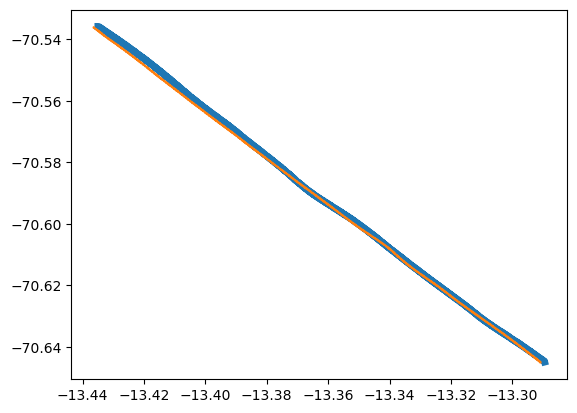

In [21]:
plt.plot(out.lon_corr, out.lat_corr, linewidth = 5)
plt.plot(ret.lon_corr, ret.lat_corr)

In [22]:
import numpy as np
import xarray as xr
from scipy.spatial import cKDTree

def latlon_to_xyz(lat, lon, R=6371000.0):
    lat_r = np.radians(lat)
    lon_r = np.radians(lon)
    x = R * np.cos(lat_r) * np.cos(lon_r)
    y = R * np.cos(lat_r) * np.sin(lon_r)
    z = R * np.sin(lat_r)
    return np.column_stack([x, y, z])

# xyz für beide Legs
xyz_out = latlon_to_xyz(out.lat_corr.values, out.lon_corr.values)
xyz_ret = latlon_to_xyz(ret.lat_corr.values, ret.lon_corr.values)

# KD-Tree über ret, out dagegen matchen
tree = cKDTree(xyz_ret)
dist, idx = tree.query(xyz_out)

threshold_m = 2000  # anpassen je nach GPS-Genauigkeit / Trackbreite
mask = dist < threshold_m

result = xr.Dataset({
    "time_out": ("match", out.time.values[mask]),
    "time_ret": ("match", ret.time.values[idx[mask]]),
    "distance_m": ("match", dist[mask]),
})

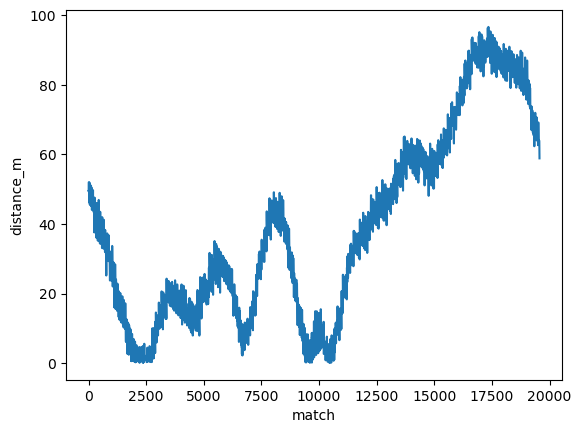

In [23]:
result.distance_m.plot()

### Segmentation documentation

For the GitHub Repos, I want to transform the segmentation list in an html table.

In [7]:
# This is for having a csv file with the times and the segment types and comments. There might be a more elegant way to do this, maybe adjust for the next campaign.

fn_in = "/Users/lakoeh001/AWINextcloud/personal/lakoeh001/campaigns/2024bacsam2/BACSAM2FlightSegmentTypes.csv"
df = pd.read_csv(fn_in, sep = ";")
byflight = df.groupby(by = "Flight")

In [8]:
flight_dict = {}
#flights = [11,12,21,22,31,32,33,4,5,6,7,8,9,10] # SANAT
flights = [1,2,3,40,41,42,5,6,7,8,9,10,11] # BACSAM II
for f in flights:
    selected_flight = byflight.get_group(f)
    flight_list = []
    for i in np.arange(len(selected_flight)):
        seg_info = selected_flight.iloc[i]
        if type(seg_info["Comment"]) == type("str"):
            comment = seg_info["Comment"]
        else:
            comment = ""
        segs = {"segment" : int(seg_info["Segment"]), "time": seg_info["Time"], "type": seg_info["Type"], "comment": comment}
        flight_list.append(segs)
    flight_dict[f] = {"segments": flight_list}

flight_segments = {"flights": flight_dict}

In [9]:
fn_out = "/Users/lakoeh001/AWI/Programmierung/bacsam2_processing/bacsam2_flight_segements.yaml" # BACSAM II
with open(fn_out, 'w') as file:
    yaml.safe_dump(flight_segments, file, sort_keys=False)

In [10]:
def generate_html_table(data, output_file):
    html = []

    html.append('<table style="font-size:90%; border-collapse:collapse;">')

    html.append("""
<thead>
<tr>
<th>Flight</th>
<th>Segment</th>
<th>Time</th>
<th>Type</th>
<th>Comment</th>
</tr>
</thead>
<tbody>
""")

    for flight_id, flight_data in data["flights"].items():

        segments = flight_data["segments"]
        rowspan = len(segments)

        for i, seg in enumerate(segments):

            html.append("<tr>")

            # Only write flight number once with rowspan
            if i == 0:
                html.append(f'<td rowspan="{rowspan}">{flight_id}</td>')

            html.append(f"<td>{seg['segment']}</td>")
            html.append(f"<td>{seg['time']}</td>")
            html.append(f"<td>{seg['type']}</td>")
            html.append(f"<td>{seg.get('comment', '')}</td>")

            html.append("</tr>")

    html.append("</tbody></table>")

    with open(output_file, "w") as f:
        f.write("\n".join(html))

    print(f"HTML table written to {output_file}")

In [11]:
# BACSAM II
fn_flightsegs = "/Users/lakoeh001/AWI/Programmierung/bacsam2_processing/bacsam2_flight_segements.yaml"
fn_html_out = "/Users/lakoeh001/AWI/Programmierung/bacsam2_processing/bacsam2_flight_segements.html"

with open(fn_flightsegs) as f:
    segments = yaml.safe_load(f)

generate_html_table(segments, fn_html_out)

HTML table written to /Users/lakoeh001/AWI/Programmierung/bacsam2_processing/bacsam2_flight_segements.html


## Determine twist angle

OPTIONAL!!!

The five-hole-probe was a bit twisted for some of the campaigns. The twist is determined here and can noted in the config file. Alpha and beta will then be corrected by the twist angle.

I normalize the pressure with the dynamic pressure to correct for different speeds. This makes sense since the dynamic pressure scales quadratically with the tas.

In the end, I didn't correct for the twisted since I assume that this is covered by the calibration of alpha and beta anyway and I also cannot distinguish tilt and twist. Therefore, I stay with the most simple version. The determined twist angle is also not very constant during different flights. Therefore, this doesn't seem to be a very robust method.

In [41]:
mus = xr.DataArray(
    np.linspace(-10, 10, 21),
    dims="mu"
)
date_dict = {1: "20240407", 2: "20240410", 3: "20240411", 40: "20240413", 41: "20240413", 42: "20240413", 5: "20240415", 6: "20240417", 7: "20240423", 8: "20240424", 9: "20240425", 10: "20240426", 11: "20240429"}

result_sum = 0
for flight in [1, 2, 3, 40, 41, 42, 5, 6, 7, 8, 9, 10, 11]:
    date = date_dict[flight]
    fn = outdir_raw+"/"+campaign+"_"+flight_date+f"_RF{flight:02}_calibrated_raw_data.nc"
    data = xr.open_dataset(fn)
    start = np.datetime64(config["flights"][flight]["start"])
    stop = np.datetime64(config["flights"][flight]["stop"])
#    sel = data.sel(time = slice(start + np.timedelta64(5,"m"),stop - np.timedelta64(5,"m")))
    sel = data.where(data.qcN > 1500)
    result = (
        (np.cos(np.deg2rad(mus)) * data.qbN - np.sin(np.deg2rad(mus)) * sel.qaN) / sel.qcN
    ).mean(axis = 1)
    test = (
        (np.cos(np.deg2rad(mus)) * data.qbN - np.sin(np.deg2rad(mus)) * sel.qaN) / sel.qcN
    )
    result_sum = result + result_sum

beta_mean = result_sum/13

In [42]:
beta_mean = xr.Dataset(coords = {"mu": mus}, data_vars = {"beta_mean": (["mu"], beta_mean.values)})

In [43]:
m,c  = np.polyfit(beta_mean.mu.values,beta_mean.beta_mean.values,1)

In [44]:
# The tilt angle is the root:
-c/m

-6.131224116755584

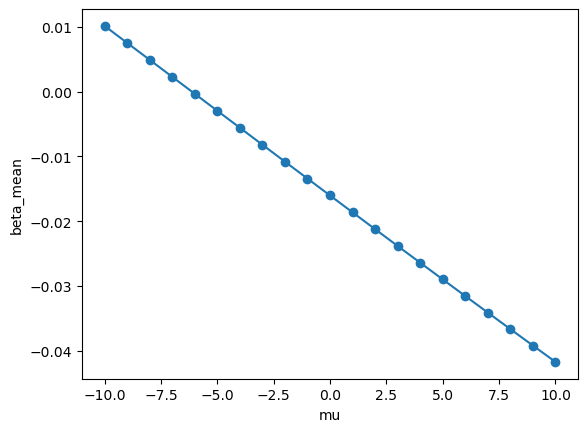

In [45]:
beta_mean.beta_mean.plot(marker = "o")

Flight 01 (20240407):  m = -0.003548,  c = -0.040915,  -c/m = -11.530493
Flight 02 (20240410):  m = -0.003047,  c = -0.030389,  -c/m = -9.973590
Flight 03 (20240411):  m = -0.004236,  c = -0.061451,  -c/m = -14.508217
Flight 05 (20240415):  m = -0.002574,  c = -0.017121,  -c/m = -6.651303
Flight 06 (20240417):  m = -0.002355,  c = 0.003311,  -c/m = 1.405740
Flight 07 (20240423):  m = -0.002397,  c = -0.010710,  -c/m = -4.467969
Flight 08 (20240424):  m = -0.002055,  c = -0.005019,  -c/m = -2.442566
Flight 09 (20240425):  m = -0.002393,  c = -0.002339,  -c/m = -0.977200
Flight 10 (20240426):  m = -0.001716,  c = 0.002900,  -c/m = 1.689735
Flight 11 (20240429):  m = -0.003943,  c = -0.021535,  -c/m = -5.462003


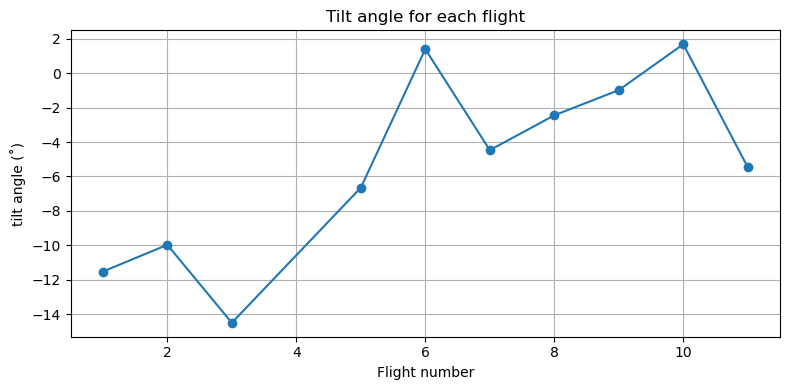

In [54]:
mus = xr.DataArray(
    np.linspace(-10, 10, 21),
    dims="mu"
)
date_dict = {1: "20240407", 2: "20240410", 3: "20240411", 40: "20240413", 41: "20240413", 42: "20240413", 5: "20240415", 6: "20240417", 7: "20240423", 8: "20240424", 9: "20240425", 10: "20240426", 11: "20240429"}

results = {}

for flight in [1, 2, 3, 5, 6, 7, 8, 9, 10, 11]:
    date = date_dict[flight]
    fn = outdir_raw+"/"+campaign+"_"+flight_date+f"_RF{flight:02}_calibrated_raw_data.nc"
    data = xr.open_dataset(fn)
    sel = data.where(data.qcN > 1700)

    result = (
        (np.cos(np.deg2rad(mus)) * data.qbN - np.sin(np.deg2rad(mus)) * sel.qaN) / sel.qcN
    ).mean(axis=1)

    beta_mean = xr.Dataset(
        coords={"mu": mus},
        data_vars={"beta_mean": (["mu"], result.values)}
    )

    m, c = np.polyfit(beta_mean.mu.values, beta_mean.beta_mean.values, 1)
    results[flight] = {"m": m, "c": c}
    print(f"Flight {flight:02} ({date}):  m = {m:.6f},  c = {c:.6f},  -c/m = {-c/m:.6f}")

# Plot
flights = list(results.keys())
zero_crossings = [-results[f]["c"] / results[f]["m"] for f in flights]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(flights, zero_crossings, marker="o", linestyle="-")
ax.set_xlabel("Flight number")
ax.set_ylabel("tilt angle (˚)")
ax.set_title("Tilt angle for each flight")
ax.grid(True)
plt.tight_layout()
plt.show()

In [86]:
date_dict = {1: "20240407", 2: "20240410", 3: "20240411", 40: "20240413", 41: "20240413", 42: "20240413", 5: "20240415", 6: "20240417", 7: "20240423", 8: "20240424", 9: "20240425", 10: "20240426", 11: "20240429"}

results = {}

for flight in [1, 2, 3, 40, 41, 42, 5, 6, 7, 8, 9, 10, 11]:
    date = date_dict[flight]
    fn = outdir_raw+"/"+campaign+"_"+flight_date+f"_RF{flight:02}_calibrated_raw_data.nc"
    data = xr.open_dataset(fn)
    sel = data.where(data.qcN > 1700)

    m, c = np.polyfit(sel.qcN.values[~np.isnan(sel.qcN.values)], sel.qbN.values[~np.isnan(sel.qcN.values)], 1)
    results[flight] = {"m": m, "c": c}

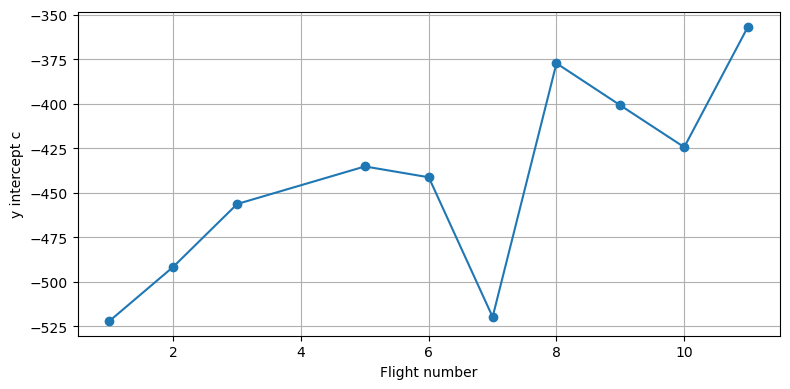

In [92]:
# Plot
flights = [1, 2, 3, 5, 6, 7, 8, 9, 10, 11]#list(results.keys())
c = [results[f]["c"] for f in flights]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(flights, c, marker="o", linestyle="-")
ax.set_xlabel("Flight number")
ax.set_ylabel("y intercept c")
ax.set_title("")
ax.grid(True)
plt.tight_layout()
plt.show()

In [90]:
np.mean(c)

-442.51070110946466

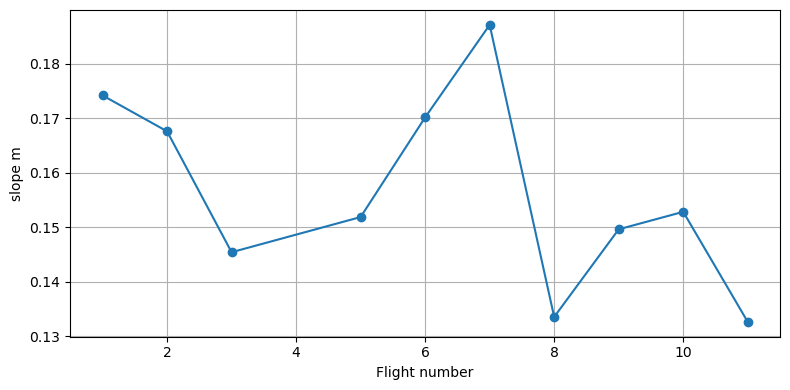

In [93]:
# Plot
flights = [1, 2, 3, 5, 6, 7, 8, 9, 10, 11]#list(results.keys())
m = [results[f]["m"] for f in flights]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(flights, m, marker="o", linestyle="-")
ax.set_xlabel("Flight number")
ax.set_ylabel("slope m")
ax.set_title("")
ax.grid(True)
plt.tight_layout()
plt.show()

In [94]:
np.mean(m)

0.1565040218051188

## Noseboom calibration

### dynamic pressure q

We do this according to the explanation in Hartmann 2018. One can either do the fit with or without offset.

In [288]:
def get_rho(ds, ds_proc):
    Rs = 287.0528
    rho = ds.psN / (Rs * ds_proc.t_air)
    return rho

In [289]:
outdir_raw = config["paths"]["outdirs"]["raw"]
outdir_nb = config["paths"]["outdirs"]["noseboom"]
campaign = config["campaign"]["name"]

In [290]:
qref = []
qi = np.array([])
gammaout = np.array([])
gammaret = np.array([])

for flight in list(config["flights"].keys()):
    flight_date = str(config["flights"][flight]["date"]).replace("-","")
    fn_in = outdir_raw+"/"+campaign+"_"+flight_date+f"_RF{flight:02}_calibrated_raw_data.nc"
    data = xr.open_dataset(fn_in)
    fn_out = outdir_nb+"/"+campaign+"_"+flight_date+f"_RF{flight:02}_noseboom_100Hz.nc"
    data_proc = xr.open_dataset(fn_out)
    try:
        cal_segments = config["flights"][flight]["calibration"]
        num = int(len(cal_segments)/2 + 1)
        for j in np.arange(1,num):
            out = data.sel(time = slice(cal_segments[f"out{j}"]["start"],cal_segments[f"out{j}"]["stop"]))
            ret = data.sel(time = slice(cal_segments[f"ret{j}"]["start"],cal_segments[f"ret{j}"]["stop"]))
            out_proc = data_proc.sel(time = slice(cal_segments[f"out{j}"]["start"],cal_segments[f"out{j}"]["stop"]))
            ret_proc = data_proc.sel(time = slice(cal_segments[f"ret{j}"]["start"],cal_segments[f"ret{j}"]["stop"]))

            out_proc["gs_corr"] = out_proc["gs"]
            ttrk_out = corr.correct_ttrk_ins_with_gps(out, out_proc,"ttrk")
            ret_proc["gs_corr"] = ret_proc["gs"]
            ttrk_ret = corr.correct_ttrk_ins_with_gps(ret, ret_proc,"ttrk")

            gamma_out = (np.deg2rad(out.thdg - ttrk_out.ttrk_corr)).mean()
            gammaout = np.append(gammaout, gamma_out.values)
            gamma_ret = (np.deg2rad(ret.thdg - ttrk_ret.ttrk_corr)).mean()
            gammaret = np.append(gammaret, gamma_ret.values)
            v_ref = 0.5 * (out_proc.gs.mean()/np.cos(gamma_out) + ret_proc.gs.mean()/np.cos(gamma_ret))
            rho = (get_rho(out, out_proc).mean() + get_rho(ret, ret_proc).mean())*0.5
            q_ref = 0.5 * rho * v_ref**2
            qref = np.append(qref, q_ref.values)
            q_i = (out.qcN.mean() + ret.qcN.mean())/2
            qi = np.append(qi, q_i.values)
    except:
        pass

In [291]:
# If fitted without offset as linear function, use this:
m = np.sum(qi * qref) / np.sum(qi * qi)
b = 0

In [292]:
m

1.0547255537506395

In [293]:
b

0

In [294]:
fit = [b , b+ qi.max() * m ]

Text(0, 0.5, '$q_\\text{ref}$ (Pa)')

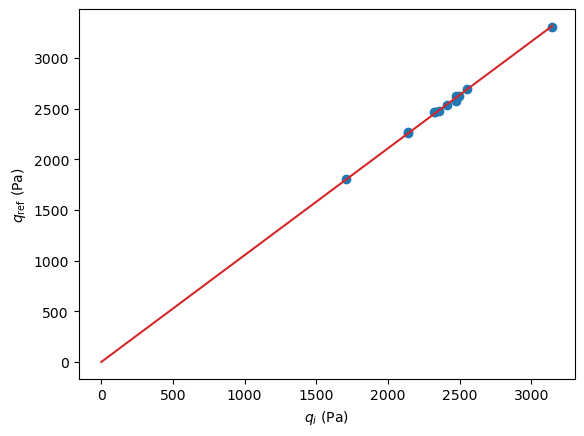

In [295]:
plt.scatter(qi, qref)
plt.plot([0, qi.max()], fit, c = "tab:red")
plt.xlabel(r"$q_i$ (Pa)")
plt.ylabel(r"$q_\text{ref}$ (Pa)")

#plt.savefig(f"{plot_dir}/q_fit.pdf")

Text(0, 0.5, '$\\gamma_\\text{ret}$ (˚)')

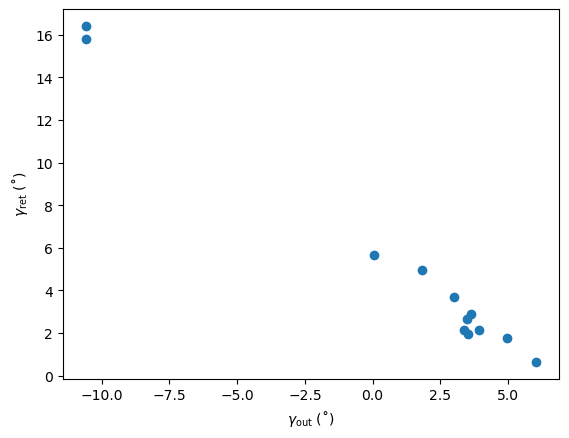

In [292]:
# This is a crosscheck if gamma_out and gamma_ret are consistent

plt.scatter(np.rad2deg(gammaout), np.rad2deg(gammaret))
#plt.plot([-12,6],[-12,6], c = "tab:red")
plt.xlabel(r"$\gamma_\text{out}$ (˚)")
plt.ylabel(r"$\gamma_\text{ret}$ (˚)")

### alpha

The alpha calibration is also explained in Hartmann et al 2028. We use version 2.

In [45]:
flights_with_calibration = [1, 8, 9, 10, 11] # BACSAM 2

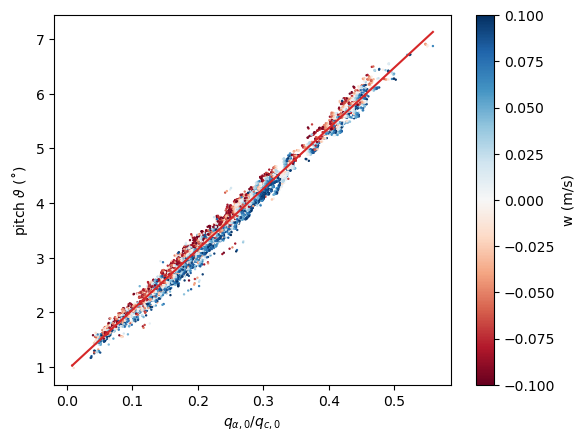

In [49]:
# Version 1: only calibration segments

pitch_all = np.array([])
qratio_all = np.array([])
wcut = 0.1
waircraft_cut = 0.05
roll_max = 2

for flight in flights_with_calibration:
    flight_date = str(config["flights"][flight]["date"]).replace("-","")
    fn_in = outdir_raw+"/"+campaign+"_"+flight_date+f"_RF{flight:02}_calibrated_raw_data.nc"
    data = xr.open_dataset(fn_in)
    fn_out = outdir_nb+"/"+campaign+"_"+flight_date+f"_RF{flight:02}_noseboom_100Hz.nc"
    data_proc = xr.open_dataset(fn_out)
    cal_segments = config["flights"][flight]["calibration"]
    num = int(len(cal_segments)/2 + 1)
    for j in np.arange(1,num):
        for dir in ["out", "ret"]:
            ds = data.sel(time = slice(np.datetime64(cal_segments[f"{dir}{j}"]["start"]),np.datetime64(cal_segments[f"{dir}{j}"]["stop"])))
            ds_proc = data_proc.sel(time = slice(cal_segments[f"{dir}{j}"]["start"],cal_segments[f"{dir}{j}"]["stop"]))
            sel = ds.where((np.abs(ds_proc.w) < wcut) & (np.abs(ds.w_bestvel) < waircraft_cut) & (np.abs(ds["roll"]) < roll_max), drop=True)
            sel_proc = ds_proc.where((np.abs(ds_proc.w) < wcut) & (np.abs(ds.w_bestvel) < waircraft_cut) & (np.abs(ds["roll"]) < roll_max), drop=True)
            pitch = sel.pit
            pitch_all = np.append(pitch_all, pitch.values)
            qratio = sel.qaN/sel.qcN
            qratio_all = np.append(qratio_all, qratio.values)
            plt.scatter(qratio,pitch, s = 0.5, c=sel_proc.w, vmin=-wcut, vmax=wcut, cmap="RdBu")

plt.xlabel(r"$q_{\alpha,0}/q_{c,0}$")
plt.ylabel(r"pitch $\vartheta$ (˚)")
plt.colorbar(label = "w (m/s)")
m, c = np.polyfit(qratio_all, pitch_all, 1)
fit = [qratio_all.min() * m + c, qratio_all.max() * m + c]
plt.plot([qratio_all.min(), qratio_all.max()], fit, c = "tab:red")

#plt.savefig(f"{plot_dir}/alpha_fit.pdf")

In [50]:
m

11.08043508287363

In [51]:
c

0.9355740042208354

CPU times: user 6.75 s, sys: 1.74 s, total: 8.48 s
Wall time: 8.54 s


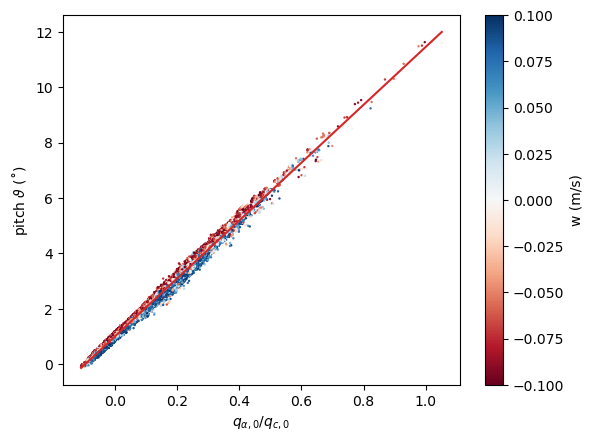

In [351]:
%%time

# Version 2: all flights. We assume that the restrictions of the roll, the vertical aircraft and wind speed already are sufficient to filter straigt flight segments.

all_flights = [1, 2, 3, 40, 41, 42, 5, 6, 7, 8, 9, 10, 11] # BACSAM 2

wcut = 0.1
waircraft_cut = 0.05
roll_max = 2

pitch_list = []
qratio_list = []
scatter_handles = []

for flight in all_flights:
    start = config["flights"][flight]["start"]
    stop = config["flights"][flight]["stop"]
    flight_date = str(config["flights"][flight]["date"]).replace("-","")
    fn_in = outdir_raw+"/"+campaign+"_"+flight_date+f"_RF{flight:02}_calibrated_raw_data.nc"
    fn_out = outdir_nb+"/"+campaign+"_"+flight_date+f"_RF{flight:02}_noseboom_100Hz.nc"

    data = xr.open_dataset(fn_in)
    data_proc = xr.open_dataset(fn_out)
    # Align datasets to common time axis before masking
    data, data_proc = xr.align(data, data_proc, join="inner")

    w_ins = corr.get_w_ins(data, start, stop)
    ds = xr.merge([data, w_ins])
    w_p6 = corr.correct_ins_with_gps(ds, "w_ins")

    # Build mask once, apply without drop=True
    mask = (
        (np.abs(data_proc.w) < wcut) &
        (np.abs(w_p6.w_ins_corr) < waircraft_cut) &
        (np.abs(ds["roll"]) < roll_max)
    )
    mask_vals = mask.values

    pitch  = ds.pit.values[mask_vals]
    qratio = (ds.qaN / ds.qcN).values[mask_vals]
    w_proc = data_proc.w.values[mask_vals]

    pitch_list.append(pitch)
    qratio_list.append(qratio)

    sc = plt.scatter(qratio, pitch, s=0.5, c=w_proc, vmin=-wcut, vmax=wcut, cmap="RdBu")
    scatter_handles.append(sc)

# Concatenate once at the end instead of appending in loop
pitch_all  = np.concatenate(pitch_list)
qratio_all = np.concatenate(qratio_list)

plt.xlabel(r"$q_{\alpha,0}/q_{c,0}$")
plt.ylabel(r"pitch $\vartheta$ (˚)")
plt.colorbar(scatter_handles[-1], label="w (m/s)")

mask_finite = np.isfinite(qratio_all) & np.isfinite(pitch_all)
m, c = np.polyfit(qratio_all[mask_finite], pitch_all[mask_finite], 1)
fit = [qratio_all.min() * m + c, qratio_all.max() * m + c]
plt.plot([qratio_all.min(), qratio_all.max()], fit, c="tab:red")

#plt.savefig(f"{plot_dir}/alpha_fit.png")

In [320]:
m # 1st iteration

10.305296000976247

In [321]:
c # 2st iteration

1.0204911515521697

In [328]:
m # 2nd iteration

10.392327409844917

In [329]:
c # 2nd iteration

1.0089381977247724

In [336]:
m # 3rd iteration

10.429600909327503

In [339]:
c # 3rd iteration

1.003638779009562

In [342]:
m # 4th iteration

10.447188669323268

In [343]:
c # 4th iteration

1.0010619612796585

In [347]:
m # 5th iteration

10.455466422792172

In [348]:
c # 5th iteration

0.999890471827656

In [352]:
m # 6th iteration

10.459536575737971

In [353]:
c # 6th iteration

0.9993065489691829

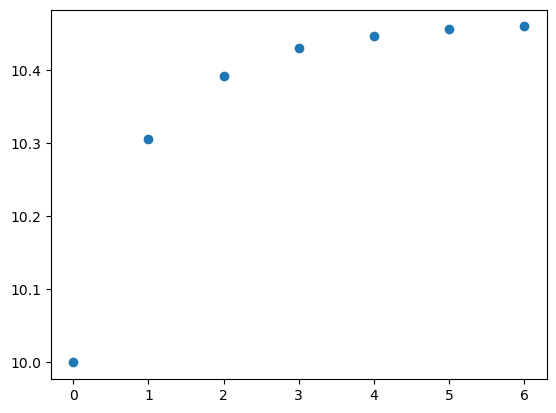

In [354]:
plt.scatter([0,1,2,3, 4, 5, 6], [10,10.305296000976247, 10.392327409844917, 10.429600909327503, 10.447188669323268, 10.455466422792172, 10.459536575737971])

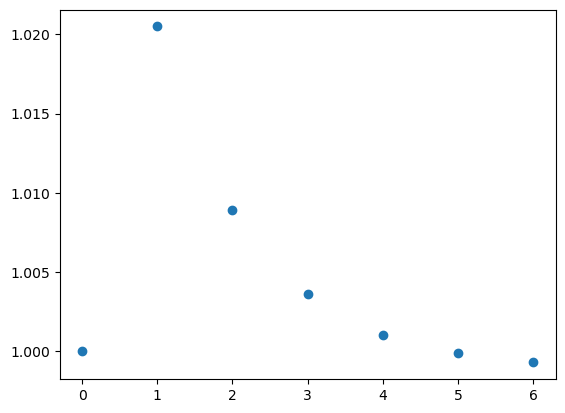

In [355]:
plt.scatter([0, 1,2,3, 4, 5, 6], [1, 1.0204911515521697, 1.0089381977247724, 1.003638779009562, 1.0010619612796585, 0.999890471827656, 0.9993065489691829])

Nice, it converges for the noseboom.

CPU times: user 27.1 s, sys: 7.04 s, total: 34.2 s
Wall time: 8.33 s


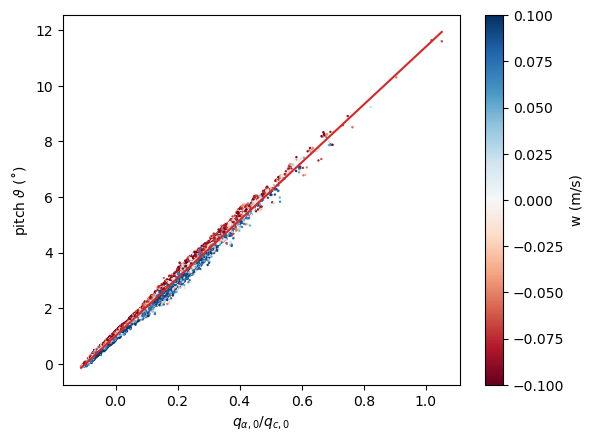

In [330]:
%%time

# Version 3: all flights seperately. This is a check if there is a drift and flights have to be handled sperately.

all_flights = [1, 2, 3, 40, 41, 42, 5, 6, 7, 8, 9, 10, 11] # BACSAM 2

wcut = 0.1
waircraft_cut = 0.05
roll_max = 2

pitch_list = []
qratio_list = []
scatter_handles = []
m_flights = []
c_flights = []

for flight in all_flights:
    start = config["flights"][flight]["start"]
    stop = config["flights"][flight]["stop"]
    flight_date = str(config["flights"][flight]["date"]).replace("-","")
    fn_in = outdir_raw+"/"+campaign+"_"+flight_date+f"_RF{flight:02}_calibrated_raw_data.nc"
    fn_out = outdir_nb+"/"+campaign+"_"+flight_date+f"_RF{flight:02}_noseboom_100Hz.nc"

    data = xr.open_dataset(fn_in)
    data_proc = xr.open_dataset(fn_out)
    # Align datasets to common time axis before masking
    data, data_proc = xr.align(data, data_proc, join="inner")

    w_ins = corr.get_w_ins(data, start, stop)
    ds = xr.merge([data, w_ins])
    w_p6 = corr.correct_ins_with_gps(ds, "w_ins")

    # Build mask once, apply without drop=True
    mask = (
        (np.abs(data_proc.w) < wcut) &
        (np.abs(w_p6.w_ins_corr) < waircraft_cut) &
        (np.abs(ds["roll"]) < roll_max)
    )
    mask_vals = mask.values

    pitch  = ds.pit.values[mask_vals]
    qratio = (ds.qaN / ds.qcN).values[mask_vals]
    w_proc = data_proc.w.values[mask_vals]

    # Per-flight fit
    mf = np.isfinite(qratio) & np.isfinite(pitch)
    m_f, c_f = np.polyfit(qratio[mf], pitch[mf], 1)
    m_flights.append(m_f)
    c_flights.append(c_f)

    pitch_list.append(pitch)
    qratio_list.append(qratio)

    sc = plt.scatter(qratio, pitch, s=0.5, c=w_proc, vmin=-wcut, vmax=wcut, cmap="RdBu")
    scatter_handles.append(sc)

# Concatenate once at the end instead of appending in loop
pitch_all  = np.concatenate(pitch_list)
qratio_all = np.concatenate(qratio_list)

plt.xlabel(r"$q_{\alpha,0}/q_{c,0}$")
plt.ylabel(r"pitch $\vartheta$ (˚)")
plt.colorbar(scatter_handles[-1], label="w (m/s)")

mask_finite = np.isfinite(qratio_all) & np.isfinite(pitch_all)
m, c = np.polyfit(qratio_all[mask_finite], pitch_all[mask_finite], 1)
fit = [qratio_all.min() * m + c, qratio_all.max() * m + c]
plt.plot([qratio_all.min(), qratio_all.max()], fit, c="tab:red")

In [331]:
np.mean(m_flights)

10.313830856468046

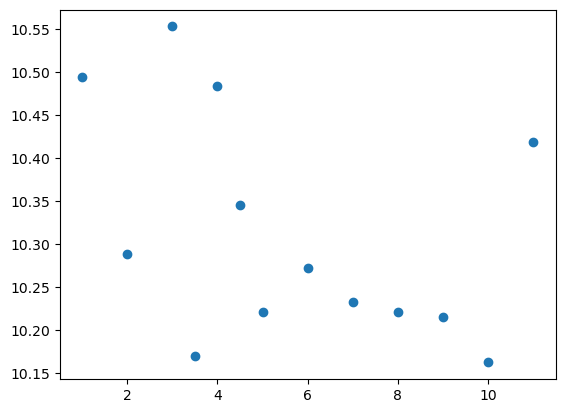

In [332]:
plt.scatter([1, 2, 3, 3.5, 4, 4.5, 5, 6, 7, 8, 9, 10, 11],m_flights)

In [333]:
np.mean(c_flights)

1.015564028713285

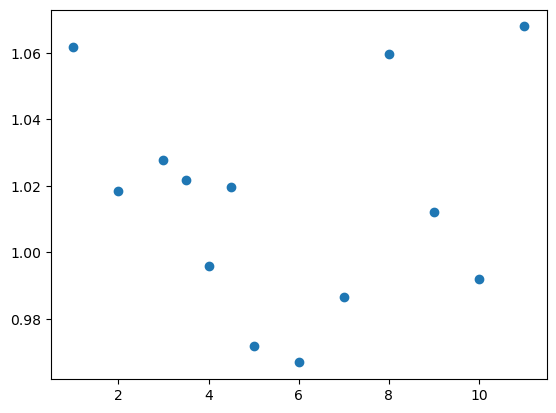

In [334]:
plt.scatter([1, 2, 3, 3.5, 4, 4.5, 5, 6, 7, 8, 9, 10, 11],c_flights)

There is no drift in the noseboom, so it's okay to consider all flights together.

### beta_0

In [356]:
pf = "noseboom"

In [357]:
calib_fn = f"{campaign_dir}/turbulence/fiveholeprobe_parameters_bacsam2.yaml"

def set_beta0(beta0):
    with open(calib_fn, "r") as f:
        calib = yaml.safe_load(f)
    calib[pf]["beta"]["a0"] = float(beta0)
    with open(calib_fn, "w") as f:
        yaml.dump(calib, f)

def delete_output_files():
    patterns = [
        outdir_nb + f"/{campaign}_*_noseboom_100Hz.nc",
    ]
    for pattern in patterns:
        for fn in glob.glob(pattern):
            os.remove(fn)
            print(f"Deleted: {fn}")

def run_polair(config_file):
    flights = "1 8 9 10 11"
    for flight in flights.split():
        subprocess.run(
            f"polair noseboom -f {flight} -c {config_file}",
            shell=True, check=True
        )

def compute_score():
    uperp_cals = []
    upara_cals = []
    
    for flight in [1, 8, 9, 10, 11]:
        flight_date = str(config["flights"][flight]["date"]).replace("-", "")
        fn_in  = outdir_raw + "/" + campaign + "_" + flight_date + f"_RF{flight:02}_calibrated_raw_data.nc"
        fn_out = outdir_nb + "/" + campaign + "_" + flight_date + f"_RF{flight:02}_noseboom_100Hz.nc"
        
        data      = xr.open_dataset(fn_in)
        data_proc = xr.open_dataset(fn_out)
        cal_segments = config["flights"][flight]["calibration"]
        num = int(len(cal_segments) / 2 + 1)
        
        for j in np.arange(1, num):
            uperp_sum = 0
            upara_sum = 0
            for dir in ["out", "ret"]:
                seg = cal_segments[f"{dir}{j}"]
                ds      = data.sel(time=slice(seg["start"], seg["stop"]))
                ds_proc = data_proc.sel(time=slice(seg["start"], seg["stop"]))
                thdg_rad = np.deg2rad(ds.thdg)
                uperp = ds_proc.u * np.cos(thdg_rad) - ds_proc.v * np.sin(thdg_rad)
                upara = ds_proc.u * np.sin(thdg_rad) + ds_proc.v * np.cos(thdg_rad)
                
                uperp_sum += uperp.mean().values
                upara_sum += upara.mean().values
            
            uperp_cals.append(uperp_sum)
            upara_cals.append(upara_sum)
    
    score_uperp = np.mean(np.abs(uperp_cals))
    score_upara = np.mean(np.abs(upara_cals))
    print(f"  mean|uperp| = {score_uperp:.4f},  mean|upara| = {score_upara:.4f}")
    return score_uperp, score_upara

In [359]:
# --- Main loop ---
beta0_values = np.linspace(-2.85,-2.75,11)
results = {}

for beta0 in beta0_values:
    print(f"\n--- beta0 = {beta0:.2f} ---")
    set_beta0(beta0)
    delete_output_files()
    run_polair(config_file)
    score_uperp, score_upara = compute_score()  # unpack tuple
    results[float(beta0)] = (score_uperp, score_upara)

best_beta0 = min(results, key=lambda b: results[b][0])
print(f"\nBest beta0: {best_beta0:.2f}  (uperp={results[best_beta0][0]:.4f}, upara={results[best_beta0][1]:.4f})")


--- beta0 = -2.85 ---
Deleted: /Users/lakoeh001/AWI/Campaigns/20240403BACSAMII/Daten/Prozessierung/noseboom/BACSAM2_20240425_RF09_noseboom_100Hz.nc
Deleted: /Users/lakoeh001/AWI/Campaigns/20240403BACSAMII/Daten/Prozessierung/noseboom/BACSAM2_20240424_RF08_noseboom_100Hz.nc
Deleted: /Users/lakoeh001/AWI/Campaigns/20240403BACSAMII/Daten/Prozessierung/noseboom/BACSAM2_20240407_RF01_noseboom_100Hz.nc
  mean|uperp| = 0.7797,  mean|upara| = 1.4933

--- beta0 = -2.84 ---
Deleted: /Users/lakoeh001/AWI/Campaigns/20240403BACSAMII/Daten/Prozessierung/noseboom/BACSAM2_20240426_RF10_noseboom_100Hz.nc
Deleted: /Users/lakoeh001/AWI/Campaigns/20240403BACSAMII/Daten/Prozessierung/noseboom/BACSAM2_20240425_RF09_noseboom_100Hz.nc
Deleted: /Users/lakoeh001/AWI/Campaigns/20240403BACSAMII/Daten/Prozessierung/noseboom/BACSAM2_20240424_RF08_noseboom_100Hz.nc
Deleted: /Users/lakoeh001/AWI/Campaigns/20240403BACSAMII/Daten/Prozessierung/noseboom/BACSAM2_20240407_RF01_noseboom_100Hz.nc
Deleted: /Users/lakoeh001/

In [360]:
set_beta0(best_beta0)

In [361]:
results

{-2.85: (0.7797423785615859, 1.49333444205882),
 -2.84: (0.7768687724169058, 1.493312249191345),
 -2.83: (0.7739951282744694, 1.4932899192730746),
 -2.8200000000000003: (0.7711214462218114, 1.4932674523046892),
 -2.81: (0.7682477263464701, 1.4932448482868723),
 -2.8: (0.7653739687359846, 1.4932764089896204),
 -2.79: (0.7679461317056181, 1.4934436713351695),
 -2.7800000000000002: (0.7729178211216023, 1.4936473333501727),
 -2.77: (0.7778895473513098, 1.4940051935923224),
 -2.76: (0.7828613102432951, 1.494361743470565),
 -2.75: (0.7878331096461088, 1.4947169829740379)}

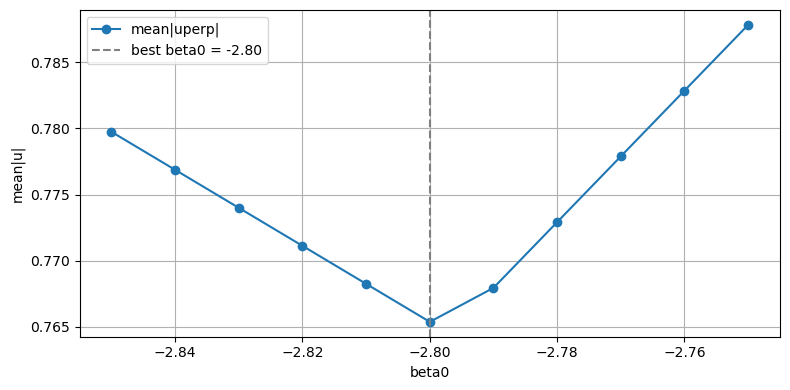

In [363]:
beta0s      = list(results.keys())
score_uperp = [results[b][0] for b in beta0s]
score_upara = [results[b][1] for b in beta0s]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(beta0s, score_uperp, marker="o", label="mean|uperp|")
#ax.plot(beta0s, score_upara, marker="o", label="mean|upara|")
ax.axvline(best_beta0, color="gray", linestyle="--", label=f"best beta0 = {best_beta0:.2f}")
ax.set_xlabel("beta0")
ax.set_ylabel("mean|u|")
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

#fig.savefig(f"{plot_dir}/beta0_determination.pdf")

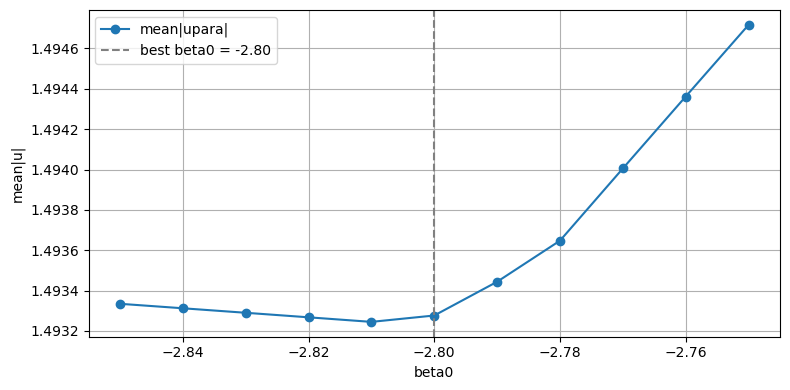

In [364]:
beta0s      = list(results.keys())
score_uperp = [results[b][0] for b in beta0s]
score_upara = [results[b][1] for b in beta0s]

fig, ax = plt.subplots(figsize=(8, 4))
#ax.plot(beta0s, score_uperp, marker="o", label="mean|uperp|")
ax.plot(beta0s, score_upara, marker="o", label="mean|upara|")
ax.axvline(best_beta0, color="gray", linestyle="--", label=f"best beta0 = {best_beta0:.2f}")
ax.set_xlabel("beta0")
ax.set_ylabel("mean|u|")
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

## T-Bird calibration

### dynamic pressure T-Bird

I don't have to do the calibration for each campaign individually. So when SANAT is processed, I can combine these two campaigns and get more calibration segments.

In [382]:
flights_with_calibration = [8, 9]
flights_with_tbird = [41, 5, 6, 7, 8, 9]

In [383]:
def get_rho(ds, ds_proc):
    Rs = 287.0528
    rho = ds.psT / (Rs * ds_proc.t_air)
    return rho

In [384]:
outdir_raw = config["paths"]["outdirs"]["raw"]
outdir_tb = config["paths"]["outdirs"]["tbird"]
campaign = config["campaign"]["name"]

In [276]:
qref = []
qi = np.array([])
gammaout = np.array([])
gammaret = np.array([])

for flight in flights_with_tbird:
    flight_date = str(config["flights"][flight]["date"]).replace("-","")
    fn_in = outdir_raw+"/"+campaign+"_"+flight_date+f"_RF{flight:02}_calibrated_raw_data.nc"
    data = xr.open_dataset(fn_in)
    fn_out = outdir_tb+"/"+campaign+"_"+flight_date+f"_RF{flight:02}_tbird_100Hz.nc"
    data_proc = xr.open_dataset(fn_out)
    try:
        cal_segments = config["flights"][flight]["calibration"]
        num = int(len(cal_segments)/2 + 1)
        if flight == 8:                                                                             # BACSAM 2
            calibs = np.arange(2,num)
        else:
            calibs = np.arange(1,num)
        for j in calibs:
            out = data.sel(time = slice(cal_segments[f"out{j}"]["start"],cal_segments[f"out{j}"]["stop"]))
            ret = data.sel(time = slice(cal_segments[f"ret{j}"]["start"],cal_segments[f"ret{j}"]["stop"]))
            out_proc = data_proc.sel(time = slice(cal_segments[f"out{j}"]["start"],cal_segments[f"out{j}"]["stop"]))
            ret_proc = data_proc.sel(time = slice(cal_segments[f"ret{j}"]["start"],cal_segments[f"ret{j}"]["stop"]))

            out_proc["ttrk_inat_corr"] = out.ttrk_inat
            ttrk_out = corr.correct_ttrk_inat_with_gps(out, out_proc)
            ret_proc["ttrk_inat_corr"] = ret.ttrk_inat
            ttrk_ret = corr.correct_ttrk_inat_with_gps(ret, ret_proc)
            
            gamma_out = (np.deg2rad(out.thdg_inat - ttrk_out.ttrk_inat_corr)).mean()
            gammaout = np.append(gammaout, gamma_out.values)
            gamma_ret = (np.deg2rad(ret.thdg_inat - ttrk_ret.ttrk_inat_corr)).mean()
            gammaret = np.append(gammaret, gamma_ret.values)
            v_ref = 0.5 * (out_proc.gs.mean()/np.cos(gamma_out) + ret_proc.gs.mean()/np.cos(gamma_ret))
            rho = (get_rho(out, out_proc).mean() + get_rho(ret, ret_proc).mean())*0.5
            q_ref = 0.5 * rho * v_ref**2
            qref = np.append(qref, q_ref.values)
            q_i = (out.qcT.mean() + ret.qcT.mean())/2
            qi = np.append(qi, q_i.values)
    except:
        pass

In [8]:
# If fitted with offset use this:
m, b = np.polyfit(qi, qref, 1)

In [376]:
# If fitted without offset as linear function, use this:
m = np.sum(qi * qref) / np.sum(qi * qi)
b = 0

In [377]:
m

1.0547255537506395

In [378]:
b

0

In [374]:
# Fehlerabschätzung
x = qi
y = qref

n = len(x)

m = np.sum(x*y) / np.sum(x**2)

res = y - m*x
s2 = np.sum(res**2) / (n - 1)

sigma_m = np.sqrt(s2 / np.sum(x**2))

In [375]:
sigma_m

0.0018915493527866542

In [280]:
fit = [b , b+ qi.max() * m ]

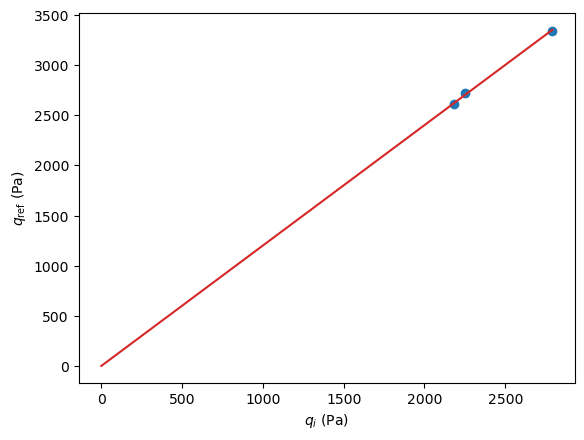

In [281]:
plt.scatter(qi, qref)
plt.plot([0, qi.max()], fit, c = "tab:red")
plt.xlabel(r"$q_i$ (Pa)")
plt.ylabel(r"$q_\text{ref}$ (Pa)")

#plt.savefig(f"{plot_dir/q_fit_tbird.pdf")

### alpha T-Bird

In [50]:
flights_with_calibration = [8, 9]

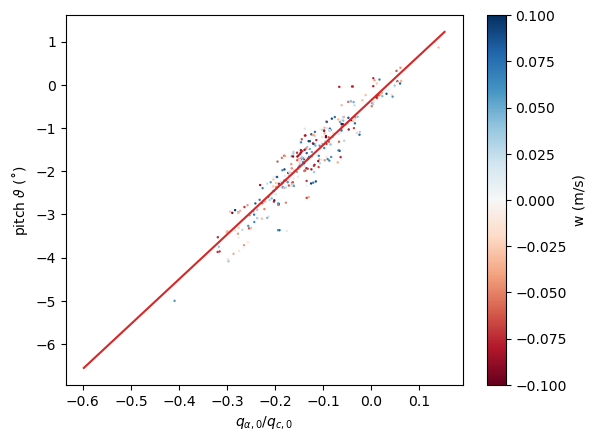

In [272]:
# Only calibration segments (this is not used)
pitch_all = np.array([])
qratio_all = np.array([])
wcut = 0.1
waircraft_cut = 0.05
roll_max = 5

for flight in flights_with_calibration:
    flight_date = str(config["flights"][flight]["date"]).replace("-","")
    fn_in = outdir_raw+"/"+campaign+"_"+flight_date+f"_RF{flight:02}_calibrated_raw_data.nc"
    data = xr.open_dataset(fn_in)
    ds = data
    fn_out = outdir_tb+"/"+campaign+"_"+flight_date+f"_RF{flight:02}_tbird_100Hz.nc"
    data_proc = xr.open_dataset(fn_out)
    ds_proc = data_proc
    cal_segments = config["flights"][flight]["calibration"]
    num = int(len(cal_segments)/2 + 1)
    if flight == 8:                                                                             # BACSAM 2
        calibs = np.arange(2,num)
    else:
        calibs = np.arange(1,num)
    for j in calibs:
        for dir in ["out", "ret"]:
            ds = data.sel(time = slice(np.datetime64(cal_segments[f"{dir}{j}"]["start"]),np.datetime64(cal_segments[f"{dir}{j}"]["stop"])))
            ds_proc = data_proc.sel(time = slice(cal_segments[f"{dir}{j}"]["start"],cal_segments[f"{dir}{j}"]["stop"]))
            sel = ds.where((np.abs(ds_proc.w) < wcut) & (np.abs(ds.w_bestvel) < waircraft_cut) & (np.abs(ds["roll"]) < roll_max), drop=True)
            sel_proc = ds_proc.where((np.abs(ds_proc.w) < wcut) & (np.abs(ds.w_bestvel) < waircraft_cut) & (np.abs(ds["roll"]) < roll_max), drop=True)
            pitch = -sel.pitch_inat
            pitch_all = np.append(pitch_all, pitch.values)
            qratio = sel.qaT/sel.qcT
            qratio_all = np.append(qratio_all, qratio.values)
    plt.scatter(qratio,pitch, s = 0.5, c=sel_proc.w, vmin=-wcut, vmax=wcut, cmap="RdBu")

plt.xlabel(r"$q_{\alpha,0}/q_{c,0}$")
plt.ylabel(r"pitch $\vartheta$ (˚)")
plt.colorbar(label = "w (m/s)")
m, c = np.polyfit(qratio_all, pitch_all, 1)
fit = [qratio_all.min() * m + c, qratio_all.max() * m + c]
plt.plot([qratio_all.min(), qratio_all.max()], fit, c = "tab:red")

#plt.savefig(f"{plot_dir/alpha_fit_tbird.pdf")

In [273]:
m

10.364769504872351

In [274]:
c

-0.35506814297048184

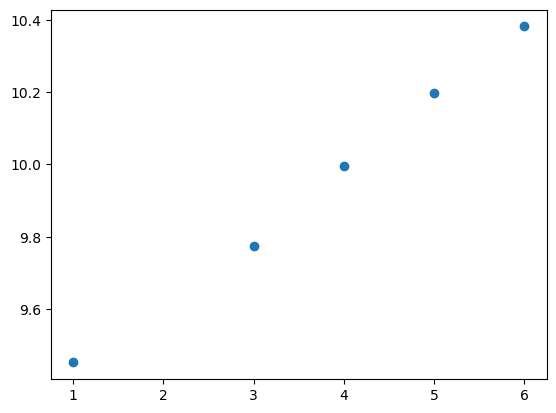

In [118]:
# Does it converge?

plt.scatter([1,3,4, 5, 6],[9.452676160564321, 9.773207959077101, 9.995281263742509, 10.197211240450214, 10.381286646930711])

CPU times: user 1.05 s, sys: 142 ms, total: 1.19 s
Wall time: 1.2 s


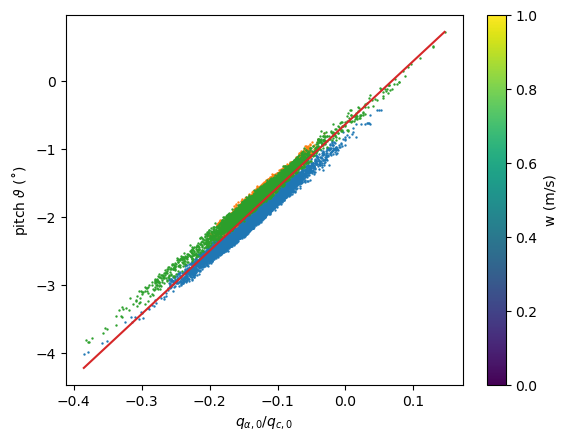

In [180]:
%%time

# Is there a cluster between for each flight, pointing to different offsets? Indeed, there is.

flights_with_tbird = [41, 5, 6, 7,8,9]
wcut = 0.1
waircraft_cut = 0.05
roll_max = 2

pitch_list = []
qratio_list = []
scatter_handles = []

for flight in flights_with_tbird:
    start = config["flights"][flight]["start_tbird"]
    stop = config["flights"][flight]["stop_tbird"]
    flight_date = str(config["flights"][flight]["date"]).replace("-","")
    fn_in = outdir_raw+"/"+campaign+"_"+flight_date+f"_RF{flight:02}_calibrated_raw_data.nc"
    fn_out = outdir_tb+"/"+campaign+"_"+flight_date+f"_RF{flight:02}_tbird_100Hz.nc"

    data = xr.open_dataset(fn_in)
    data_proc = xr.open_dataset(fn_out)
    # Align datasets to common time axis before masking
    data, data_proc = xr.align(data, data_proc, join="inner")

    w_inat = data.h_inat.diff("time")/0.01
    w_inat = w_inat.to_dataset(name = "w_inat")
    ds = xr.merge([data, w_inat])

    # Build mask once, apply without drop=True
    mask = (
        (np.abs(data_proc.w) < wcut) &
        (np.abs(ds.w_inat) < waircraft_cut) &
        (np.abs(ds["roll_inat"]) < roll_max)
    )
    mask_vals = mask.values

    pitch  = -ds.pitch_inat.values[mask_vals]
    qratio = (ds.qaT / ds.qcT).values[mask_vals]
    w_proc = data_proc.w.values[mask_vals]

    pitch_list.append(pitch)
    qratio_list.append(qratio)

    sc = plt.scatter(qratio, pitch, s=0.5)
#    sc = plt.scatter(qratio, pitch, s=0.5, c=w_proc, vmin=-wcut, vmax=wcut, cmap="RdBu")
    scatter_handles.append(sc)

# Concatenate once at the end instead of appending in loop
pitch_all  = np.concatenate(pitch_list)
qratio_all = np.concatenate(qratio_list)

plt.xlabel(r"$q_{\alpha,0}/q_{c,0}$")
plt.ylabel(r"pitch $\vartheta$ (˚)")
plt.colorbar(scatter_handles[-1], label="w (m/s)")

mask_finite = np.isfinite(qratio_all) & np.isfinite(pitch_all)
m, c = np.polyfit(qratio_all[mask_finite], pitch_all[mask_finite], 1)
fit = [qratio_all.min() * m + c, qratio_all.max() * m + c]
plt.plot([qratio_all.min(), qratio_all.max()], fit, c="tab:red")

In [181]:
m

9.319228135391276

In [182]:
c

-0.6316744863586898

In [155]:
m

8.166943831275299

In [156]:
c

-0.8725519757682242

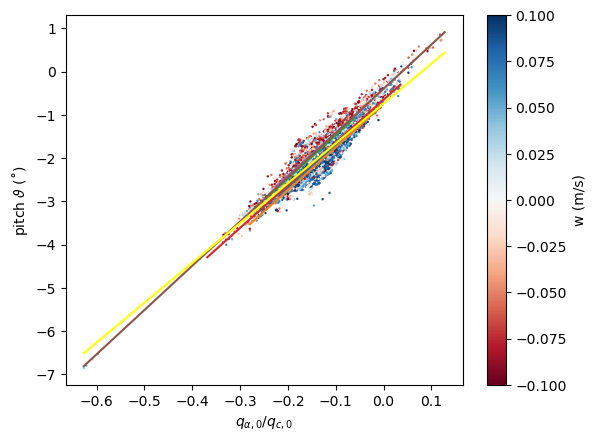

In [385]:
flights_with_tbird = [41, 5, 6, 7, 8, 9]
wcut = 0.1
waircraft_cut = 0.05
roll_max = 2
pitch_list = []
qratio_list = []
scatter_handles = []
m_flights = []
c_flights = []

# I only take straight segments
segments_dict = {
    41: [3, 5, 7, 9, 11, 13, 15, 17],
    5:  [7, 9, 11],
    6:  [4, 6, 8, 12, 14],
    7:  [6, 8, 10, 13, 15],
    8:  [12, 14, 16],
    9:  [4, 6, 8, 10, 12, 14],
}

for flight in flights_with_tbird:
    flight_date = str(config["flights"][flight]["date"]).replace("-", "")
    fn_in  = outdir_raw+"/"+campaign+"_"+flight_date+f"_RF{flight:02}_calibrated_raw_data.nc"
    fn_out = outdir_tb +"/"+campaign+"_"+flight_date+f"_RF{flight:02}_tbird_100Hz.nc"
    data      = xr.open_dataset(fn_in).load()
    data_proc = xr.open_dataset(fn_out).load()

    # Select segments
    seg_mask = np.isin(data_proc.segment.values, segments_dict[flight])
    data_proc = data_proc.isel(time=seg_mask)

    # Match data to data_proc time axis — fast nearest-neighbor lookup
    data = data.sel(time=data_proc.time, method="nearest")

    # Compute w_inat in numpy directly
    h = data.h_inat.values
    w_inat = np.empty_like(h)
    w_inat[:-1] = np.diff(h) / 0.01
    w_inat[-1]  = np.nan

    # Build mask in numpy
    mask_vals = (
        (np.abs(data_proc.w.values) < wcut) &
        (np.abs(w_inat) < waircraft_cut) &
        (np.abs(data.roll_inat.values) < roll_max)
    )

    pitch  = -data.pitch_inat.values[mask_vals]
    qratio = (data.qaT.values / data.qcT.values)[mask_vals]
    w_proc = data_proc.w.values[mask_vals]

    pitch_list.append(pitch)
    qratio_list.append(qratio)

    # Per-flight fit
    mf = np.isfinite(qratio) & np.isfinite(pitch)
    m_f, c_f = np.polyfit(qratio[mf], pitch[mf], 1)
    m_flights.append(m_f)
    c_flights.append(c_f)

    sc = plt.scatter(qratio, pitch, s=0.5, c=w_proc, vmin=-wcut, vmax=wcut, cmap="RdBu")
    scatter_handles.append(sc)
    fit = [qratio.min() * m_f + c_f, qratio.max() * m_f + c_f]
    plt.plot([qratio.min(), qratio.max()], fit)

# Concatenate and overall fit
pitch_all  = np.concatenate(pitch_list)
qratio_all = np.concatenate(qratio_list)

mask_finite = np.isfinite(qratio_all) & np.isfinite(pitch_all)
m, c = np.polyfit(qratio_all[mask_finite], pitch_all[mask_finite], 1)
fit = [qratio_all.min() * m + c, qratio_all.max() * m + c]

plt.xlabel(r"$q_{\alpha,0}/q_{c,0}$")
plt.ylabel(r"pitch $\vartheta$ (˚)")
plt.colorbar(scatter_handles[-1], label="w (m/s)")
plt.plot([qratio_all.min(), qratio_all.max()], fit, c="yellow")

#plt.savefig(f"{plot_dir/alpha_fit_tbird.png")

In [386]:
from scipy.stats import linregress

x = qratio_all
y = pitch_all

res = linregress(x, y)

slope = res.slope
intercept = res.intercept

slope_err = res.stderr
intercept_err = res.intercept_stderr

In [258]:
m # starting point 10 and -0.5

9.229596451686875

In [259]:
np.mean(m_flights) # starting point 10 and -0.5

9.977509593057327

In [260]:
np.mean(c_flights) # starting point 10 and -0.5

-0.5675842719854689

In [261]:
c # starting point 10 and -0.5

-0.7380858109166986

In [263]:
m # 2nd iteration

9.212503275253397

In [264]:
np.mean(m_flights) # 2nd iteration

9.961817049802375

In [265]:
np.mean(c_flights) # 2nd iteration

-0.5700461933998934

In [266]:
c # 2nd iteration

-0.7403039107446544

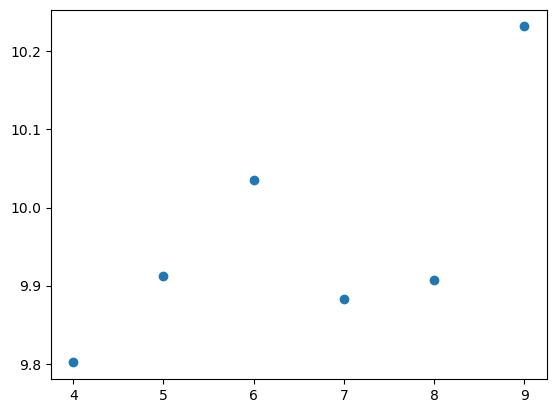

In [267]:
# How is the scattering for the different flights? m seems to be pretty consistent

plt.scatter([4, 5, 6, 7, 8, 9],m_flights)

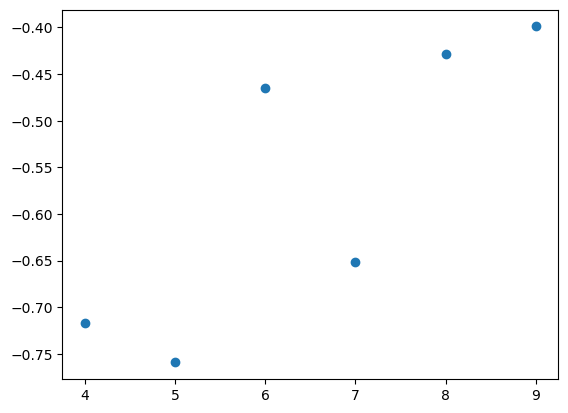

In [268]:
# But the offset is doing quite some jumps

plt.scatter([4, 5, 6, 7, 8, 9],c_flights)

Das ist der Einbaufehler zwischen Fünglochsonde und iNAT

### beta_0 T-Bird

In [235]:
pf = "tbird"

calib_fn = f"{campaign_dir}/turbulence/fiveholeprobe_parameters_bacsam2.yaml"

def set_beta0(beta0):
    with open(calib_fn, "r") as f:
        calib = yaml.safe_load(f)
    calib[pf]["beta"]["a0"] = float(beta0)
    with open(calib_fn, "w") as f:
        yaml.dump(calib, f)

def delete_output_files():
    patterns = [
        outdir_tb + f"/{campaign}_*_tbird_100Hz.nc",
    ]
    for pattern in patterns:
        for fn in glob.glob(pattern):
            os.remove(fn)
            print(f"Deleted: {fn}")

def run_polair(config_file):
    flights = [8, 9]
    for flight in flights:
        subprocess.run(
            f"polair tbird -f {flight} -c {config_file}",
            shell=True, check=True
        )

def compute_score():
    uperp_cals = []
    upara_cals = []
    
    for flight in [8, 9]:
        flight_date = str(config["flights"][flight]["date"]).replace("-", "")
        fn_in  = outdir_raw + "/" + campaign + "_" + flight_date + f"_RF{flight:02}_calibrated_raw_data.nc"
        fn_out = outdir_tb + "/" + campaign + "_" + flight_date + f"_RF{flight:02}_tbird_100Hz.nc"
        
        data      = xr.open_dataset(fn_in)
        data_proc = xr.open_dataset(fn_out)
        cal_segments = config["flights"][flight]["calibration"]
        num = int(len(cal_segments) / 2 + 1)
        if flight == 8:                                                                             # BACSAM 2
            calibs = np.arange(2,num)
        else:
            calibs = np.arange(1,num)
        for j in calibs:
            uperp_sum = 0
            upara_sum = 0
            for dir in ["out", "ret"]:
                seg = cal_segments[f"{dir}{j}"]
                ds      = data.sel(time=slice(seg["start"], seg["stop"]))
                ds_proc = data_proc.sel(time=slice(seg["start"], seg["stop"]))

                # Get corrected true track:
#                da = corr.reverse_antennas(ds, "ttrk_inat", True).rename("ttrk_inat_corr")
#                data_corr = da.to_dataset()
#                thdg = (ds.thdg_inat + 180)#corr.correct_ttrk_inat_with_gps(ds, data_corr)
                thdg_rad = np.deg2rad(ds.thdg_inat + 180)#ttrk_corr.ttrk_inat_corr)
                uperp = ds_proc.u * np.cos(thdg_rad) - ds_proc.v * np.sin(thdg_rad)
                upara = ds_proc.u * np.sin(thdg_rad) + ds_proc.v * np.cos(thdg_rad)
                
                uperp_sum += uperp.mean().values
                upara_sum += upara.mean().values
            
            uperp_cals.append(uperp_sum)
            upara_cals.append(upara_sum)
    
    score_uperp = np.mean(np.abs(uperp_cals))
    score_upara = np.mean(np.abs(upara_cals))
    print(f"  mean|uperp| = {score_uperp:.4f},  mean|upara| = {score_upara:.4f}")
    return score_uperp, score_upara

In [269]:
# --- Main loop ---
beta0_values = np.linspace(-1.4,-1.3,11)
results = {}

for beta0 in beta0_values:
    print(f"\n--- beta0 = {beta0:.3f} ---")
    set_beta0(beta0)
    delete_output_files()
    run_polair(config_file)
    score_uperp, score_upara = compute_score()  # unpack tuple
    results[float(beta0)] = (score_uperp, score_upara)

best_beta0 = min(results, key=lambda b: results[b][0])
print(f"\nBest beta0: {best_beta0:.3f}  (uperp={results[best_beta0][0]:.4f}, upara={results[best_beta0][1]:.4f})")


--- beta0 = -1.400 ---
Deleted: /Users/lakoeh001/AWI/Campaigns/20240403BACSAMII/Daten/Prozessierung/tbird/BACSAM2_20240417_RF06_tbird_100Hz.nc
Deleted: /Users/lakoeh001/AWI/Campaigns/20240403BACSAMII/Daten/Prozessierung/tbird/BACSAM2_20240415_RF05_tbird_100Hz.nc
Deleted: /Users/lakoeh001/AWI/Campaigns/20240403BACSAMII/Daten/Prozessierung/tbird/BACSAM2_20240413_RF41_tbird_100Hz.nc
Deleted: /Users/lakoeh001/AWI/Campaigns/20240403BACSAMII/Daten/Prozessierung/tbird/BACSAM2_20240423_RF07_tbird_100Hz.nc
Deleted: /Users/lakoeh001/AWI/Campaigns/20240403BACSAMII/Daten/Prozessierung/tbird/BACSAM2_20240425_RF09_tbird_100Hz.nc
Deleted: /Users/lakoeh001/AWI/Campaigns/20240403BACSAMII/Daten/Prozessierung/tbird/BACSAM2_20240424_RF08_tbird_100Hz.nc
  mean|uperp| = 1.2458,  mean|upara| = 4.8577

--- beta0 = -1.390 ---
Deleted: /Users/lakoeh001/AWI/Campaigns/20240403BACSAMII/Daten/Prozessierung/tbird/BACSAM2_20240425_RF09_tbird_100Hz.nc
Deleted: /Users/lakoeh001/AWI/Campaigns/20240403BACSAMII/Daten/Pro

In [270]:
set_beta0(best_beta0)

In [271]:
results

{-1.4: (1.2458231742622428, 4.857658902781492),
 -1.39: (1.2364085757573595, 4.858142736035157),
 -1.38: (1.230103784275988, 4.8586223472876116),
 -1.3699999999999999: (1.2355931916823513, 4.859097736524243),
 -1.3599999999999999: (1.241082610918194, 4.859568903730572),
 -1.35: (1.2465720418163022, 4.860035848892243),
 -1.34: (1.2520614842094564, 4.860498571995033),
 -1.33: (1.257550937930438, 4.86095707302485),
 -1.32: (1.2630404028120354, 4.861411351967725),
 -1.31: (1.2685298786870194, 4.861861408809818),
 -1.3: (1.2740193653881777, 4.862307243537423)}

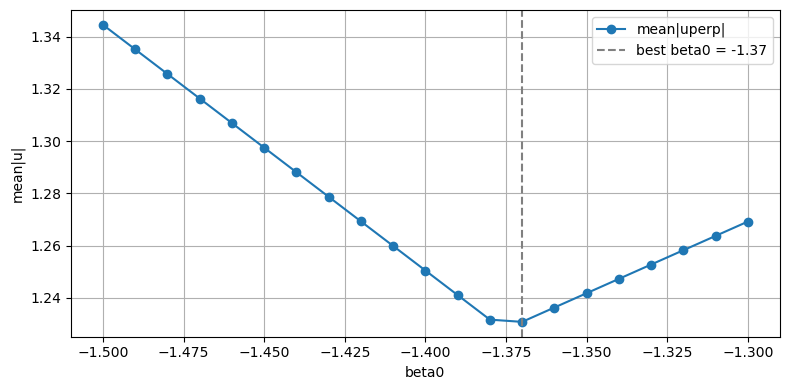

In [241]:
beta0s      = list(results.keys())
score_uperp = [results[b][0] for b in beta0s]
score_upara = [results[b][1] for b in beta0s]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(beta0s, score_uperp, marker="o", label="mean|uperp|")
#ax.plot(beta0s, score_upara, marker="o", label="mean|upara|")
ax.axvline(best_beta0, color="gray", linestyle="--", label=f"best beta0 = {best_beta0:.2f}")
ax.set_xlabel("beta0")
ax.set_ylabel("mean|u|")
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

#fig.savefig(f"{plot_dir/beta0_determination_tbird.pdf")

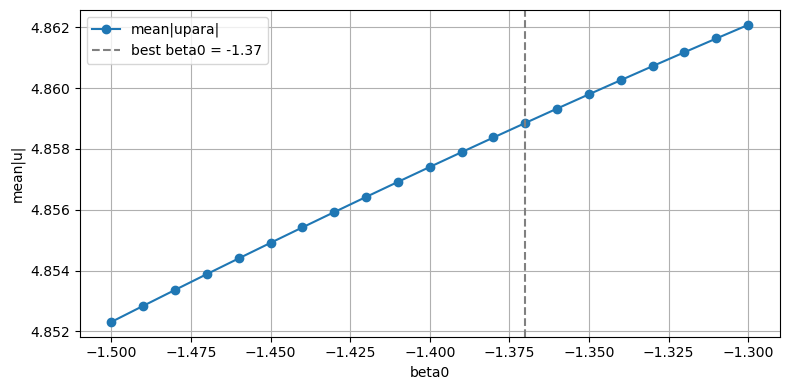

In [242]:
beta0s      = list(results.keys())
score_uperp = [results[b][0] for b in beta0s]
score_upara = [results[b][1] for b in beta0s]

fig, ax = plt.subplots(figsize=(8, 4))
#ax.plot(beta0s, score_uperp, marker="o", label="mean|uperp|")
ax.plot(beta0s, score_upara, marker="o", label="mean|upara|")
ax.axvline(best_beta0, color="gray", linestyle="--", label=f"best beta0 = {best_beta0:.2f}")
ax.set_xlabel("beta0")
ax.set_ylabel("mean|u|")
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

# Check for time offsets

instruments where the time is manually adjusted might have time offsets. These can be noted in the config file.

In [13]:
def check_time_shift(p1, p2, max_lag_seconds=60, plot=True):
    """
    p1, p2: xarray DataArrays with a 'time' dimension
    Detects time shift between two pressure signals via cross-correlation.
    """
    
    # 1. Interpolate p2 onto p1's time axis (common grid required)
    p2_interp = p2.interp(time=p1.time, method="linear")

    # 2. Remove slow trends — only fluctuations carry timing info
    #    (high-pass: subtract a rolling mean)
    window = 600  # samples; tune to your sampling rate
    p1_anom = p1 - p1.rolling(time=window, center=True, min_periods=1).mean()
    p2_anom = p2_interp - p2_interp.rolling(time=window, center=True, min_periods=1).mean()

    # 3. Drop NaNs (must be same length)
    a = p1_anom.values
    b = p2_anom.values
    mask = np.isfinite(a) & np.isfinite(b)
    a, b = a[mask], b[mask]

    # 4. Normalize
    a = (a - a.mean()) / a.std()
    b = (b - b.mean()) / b.std()

    # 5. Cross-correlation
    corr = signal.correlate(a, b, mode="full")
    lags = signal.correlation_lags(len(a), len(b), mode="full")

    # Convert lags from samples to seconds
    dt = float(p1.time.diff("time").median()) / 1e9  # ns → seconds
    lags_sec = lags * dt

    # Restrict to max_lag window
    mask_lag = np.abs(lags_sec) <= max_lag_seconds
    corr_windowed = corr[mask_lag]
    lags_windowed = lags_sec[mask_lag]

        # Envelope of the cross-correlation
#    envelope = np.abs(hilbert(corr_windowed))
#    best_lag = lags_windowed[np.argmax(envelope)]
    #print(f"Lag from envelope: {best_lag:.2f} s")
    best_lag = lags_windowed[np.argmax(corr_windowed)]
    print(f"Estimated time shift: {best_lag:.2f} s  (postive → p1 leads p2, i.e. p2 needs to be shifted by {best_lag * 1000:.0f} ms)")

    if plot:
        fig, axes = plt.subplots(2, 1, figsize=(10, 6))

        axes[0].plot(p1.time, p1_anom, label="proc.p_air", alpha=0.7)
        axes[0].plot(p2_interp.time, p2_anom, label="out_ds.p_air", alpha=0.7)
        axes[0].set_ylabel("pressure anomaly")
        axes[0].legend()
        axes[0].set_title("Detrended pressure fluctuations")

        axes[1].plot(lags_windowed, corr_windowed)
        axes[1].axvline(best_lag, color="red", linestyle="--",
                        label=f"peak lag = {best_lag:.2f} s")
        axes[1].set_xlabel("lag (s)")
        axes[1].set_ylabel("cross-correlation")
        axes[1].set_title("Cross-correlation (restricted to ±{max_lag_seconds} s)")
        axes[1].legend()

        plt.tight_layout()
        plt.show()

    return best_lag

In [41]:
flight = 9
pf = "mcpc"
if pf == "partector_tbird":
    dev = "partector_dms_tbird"
else:
    dev = pf
config_file = "/Users/lakoeh001/AWI/Programmierung/bacsam2_processing/config_bacsam2.yaml"

In [42]:
config = h.import_dictionary(config_file)
outdir_totest = config["paths"]["outdirs"][pf]
flight_date = str(config["flights"][flight]["date"]).replace("-","")
campaign = config["campaign"]["name"]
if pf[-5:] == "tbird":
    outdir_nb = config["paths"]["outdirs"]["tbird"]
    fn_ref = outdir_nb+"/"+campaign+"_"+flight_date+f"_RF{flight:02}_tbird_100Hz.nc"
else:
    outdir_nb = config["paths"]["outdirs"]["noseboom"]
    fn_ref = outdir_nb+"/"+campaign+"_"+flight_date+f"_RF{flight:02}_noseboom_100Hz.nc"
fn = outdir_totest+"/"+campaign+"_"+flight_date+f"_RF{flight:02}_{pf}.nc"

ref = xr.open_dataset(fn_ref)
totest = xr.open_dataset(fn)

Estimated time shift: 0.00 s  (postive → p1 leads p2, i.e. p2 needs to be shifted by 0 ms)


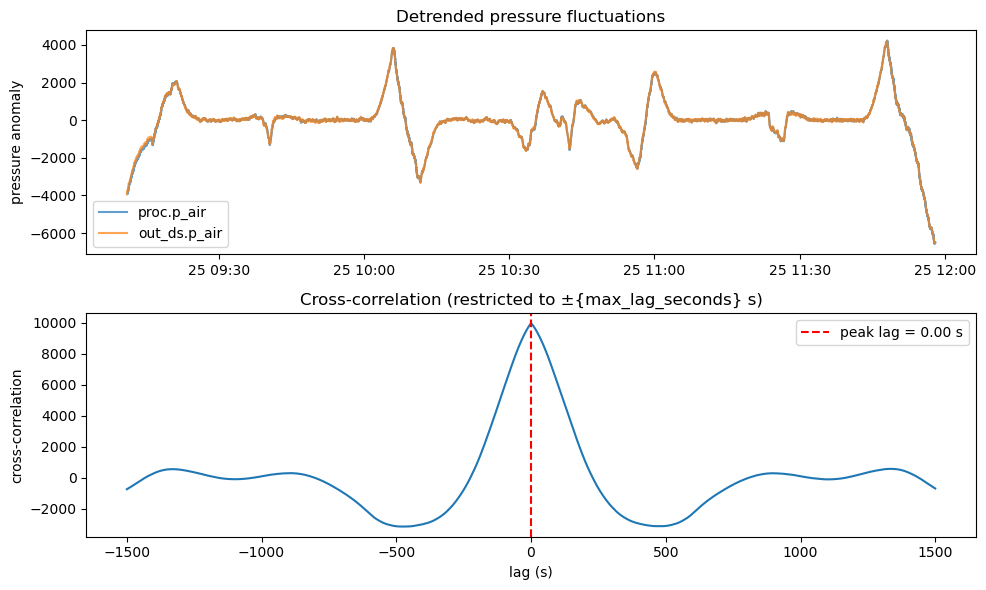

In [82]:
lag = check_time_shift(totest.p_amb, ref.p_air, max_lag_seconds=1500)

# Plot devices

## Partector

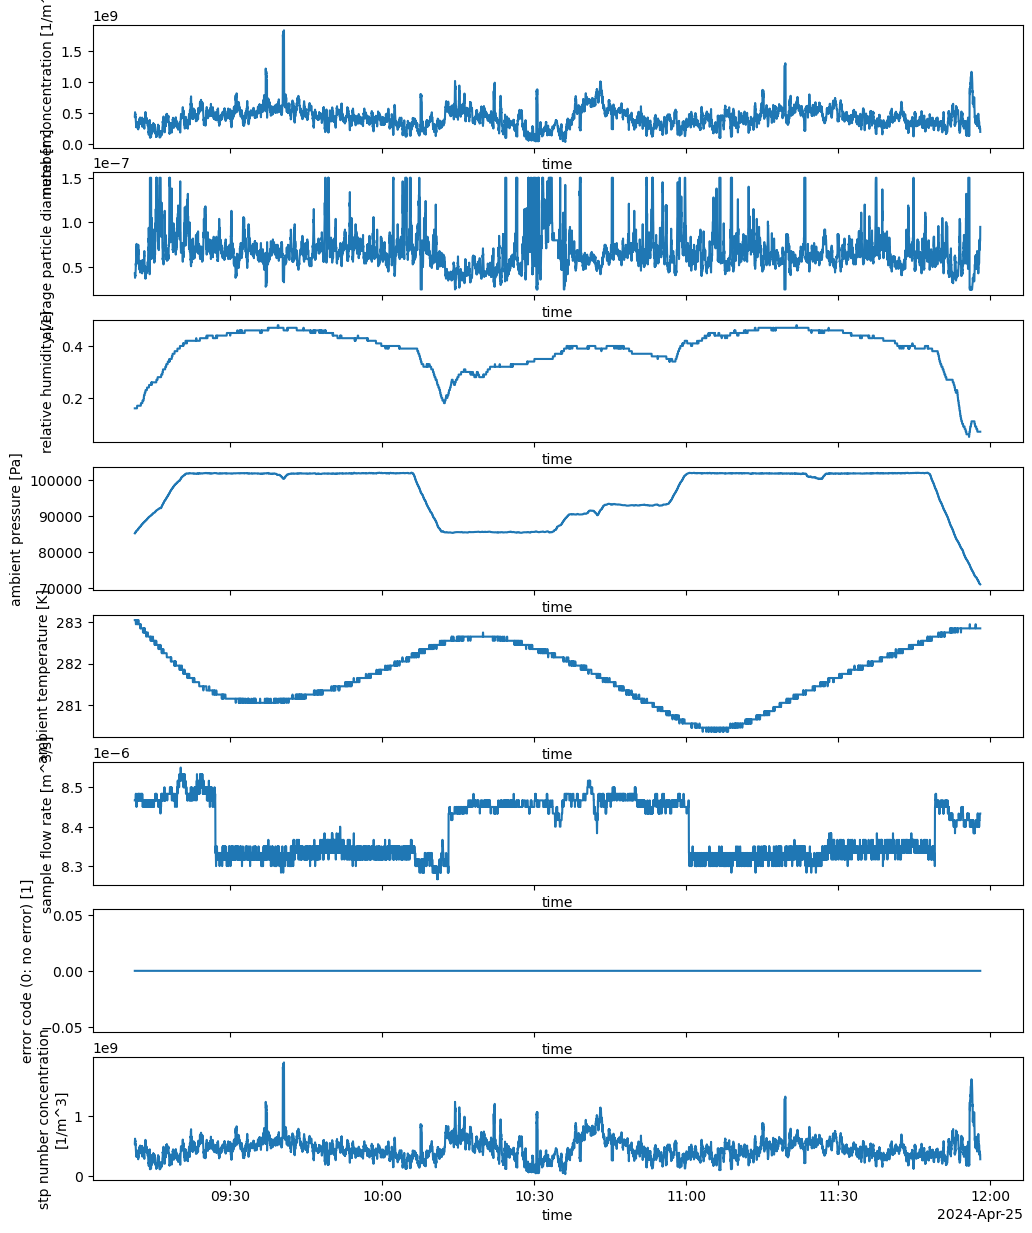

In [20]:
# Partector
fig, axs = plt.subplots(8,1,figsize=(12,15),sharex=True)

for v, ax in zip(list(totest.keys()), fig.get_axes()):
    totest[v].plot(ax = ax)

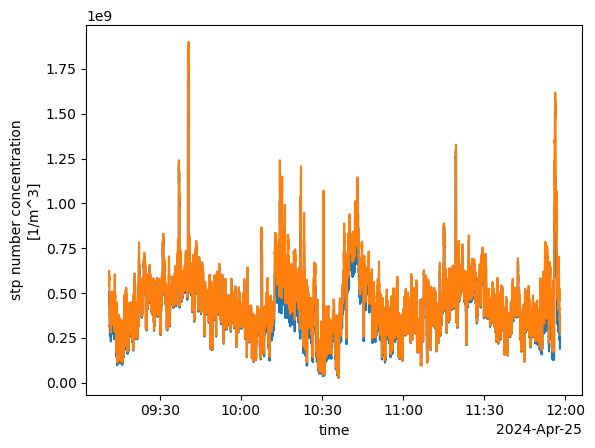

In [21]:
totest.number_conc.plot()
totest.number_conc_stp.plot()

## MCPC

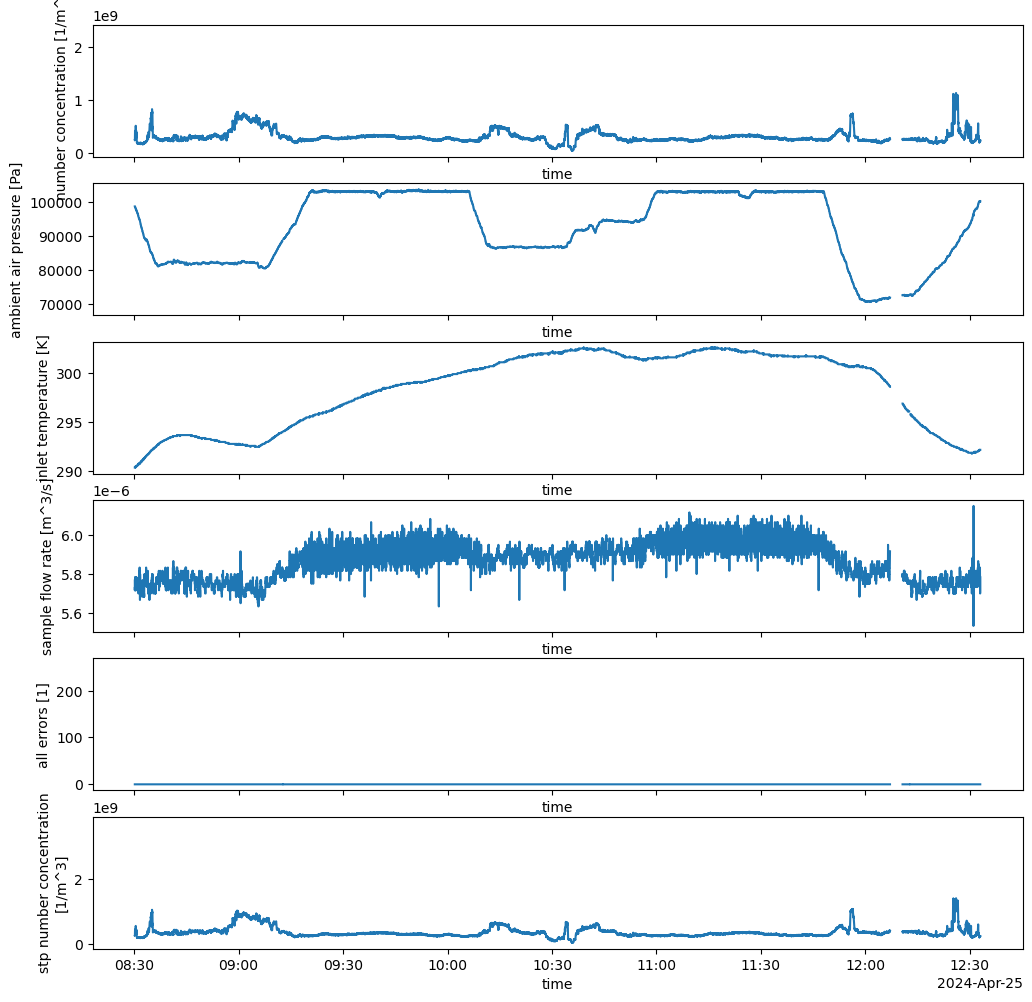

In [43]:
#MCPC
fig, axs = plt.subplots(6,1,figsize=(12,12),sharex=True)

for v, ax in zip(list(totest.keys()), fig.get_axes()):
    totest[v].plot(ax = ax)

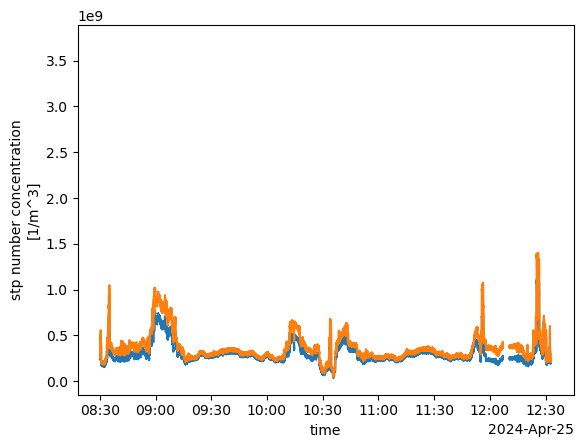

In [11]:
totest.number_conc.plot()
totest.number_conc_stp.plot()

In [47]:
totest

<xarray.Dataset>
Dimensions:          (time: 14580)
Coordinates:
  * time             (time) datetime64[ns] 2024-04-25T08:30:00.160000 ... 202...
    segment          (time) int64 ...
    lat              (time) float64 ...
    lon              (time) float64 ...
    alt              (time) float64 ...
Data variables:
    number_conc      (time) float64 ...
    p_amb            (time) float64 ...
    t_amb            (time) float64 ...
    flow_rate        (time) float64 ...
    error            (time) float64 ...
    number_conc_stp  (time) float64 ...
Attributes: (12/13)
    title:        BACSAM 2 campaign with Polar 6: aMCPC of RF09 (2024-04-25)
    author:       Laura Köhler, Zsofia Juranyi
    institution:  Alfred-Wegener-Institut
    contact:      laura.koehler@awi.de
    date:         2026-07-01
    serial:       26
    ...           ...
    doi:          tba
    conventions:  CF-1.7
    processing:   processed with polair (https://github.com/LauraKoehler/pola...
    comment:      part of <doi>
    campaign:     BACSAM2
    platform:     Polar 6

## KT19

In [28]:
ds = xr.open_dataset("/Users/lakoeh001/AWI/Campaigns/20240403BACSAMII/Daten/Prozessierung/kt19/BACSAM2_20240429_RF11_kt19.nc")

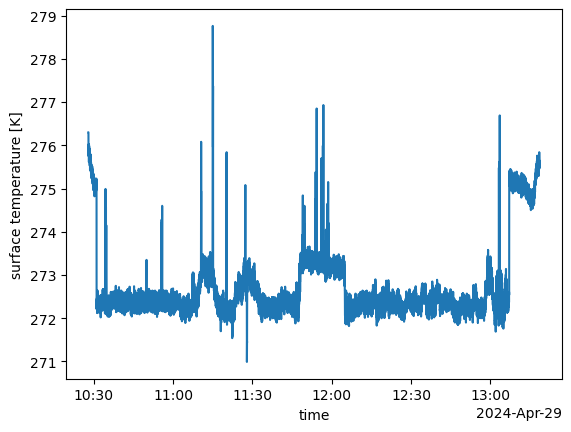

In [5]:
ds.t_surface.plot()

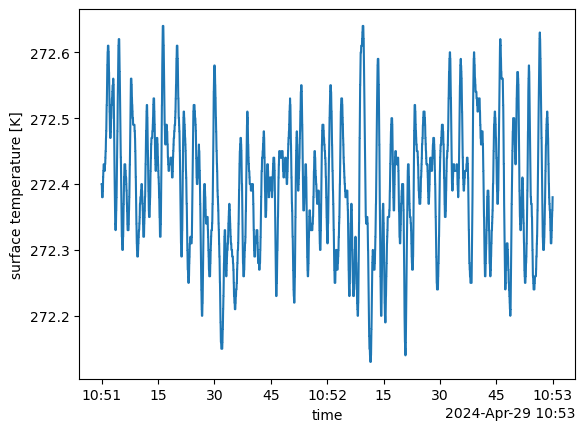

In [6]:
ds.groupby("segment")[5].t_surface.plot()

In [37]:
ds.time.diff("time").mean()

<xarray.DataArray 'time' ()>
array(19997713, dtype='timedelta64[ns]')

In [38]:
19997713/10**9

0.019997713

In [39]:
1/0.019997713

50.005718153870895

In [40]:
ds

<xarray.Dataset>
Dimensions:    (time: 511559)
Coordinates:
  * time       (time) datetime64[ns] 2024-04-29T10:28:00.005751 ... 2024-04-2...
    segment    (time) int64 ...
    lat        (time) float64 ...
    lon        (time) float64 ...
    alt        (time) float64 ...
Data variables:
    t_surface  (time) float64 ...
Attributes: (12/13)
    title:        BACSAM 2 campaign with Polar 6: KT19 of RF11 (2024-04-29)
    author:       Laura Köhler, Zsofia Juranyi
    institution:  Alfred-Wegener-Institut
    contact:      laura.koehler@awi.de
    date:         2026-07-01
    serial:       3071
    ...           ...
    doi:          tba
    conventions:  CF-1.7
    processing:   processed with polair (https://github.com/LauraKoehler/pola...
    comment:      part of <doi>
    campaign:     BACSAM2
    platform:     Polar 6

## radiation

In [48]:
ds = xr.open_dataset("/Users/lakoeh001/AWI/Campaigns/20240403BACSAMII/Daten/Prozessierung/radiation/BACSAM2_20240425_RF09_radiation.nc")

In [26]:
sigma = 5.670374 * 10**(-8)
blackbody = None
for v in ["lw_up", "lw_down", "sw_up", "sw_down"]:
    blackbodyrad = (sigma * ds[f"t_{v}"]**4)
    try:
        blackbody[f"{v}_bb"] = blackbodyrad
    except:
        blackbody = blackbodyrad.to_dataset(name = f"{v}_bb")

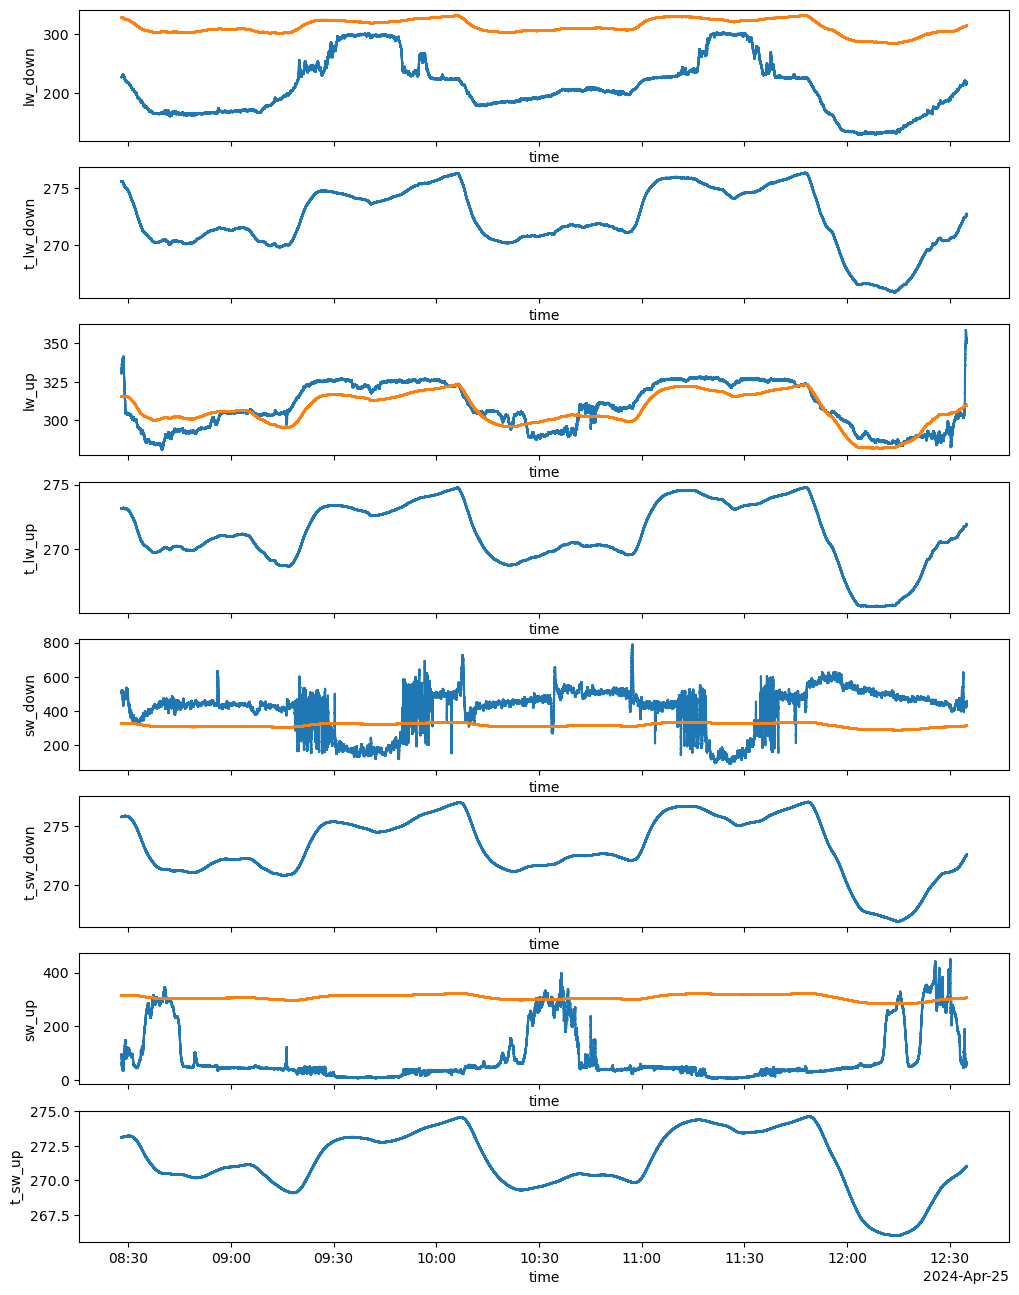

In [27]:
#MCPC
fig, axs = plt.subplots(8,1,figsize=(12,16),sharex=True)

for v, ax in zip(list(ds.keys()), fig.get_axes()):
    ds[v].plot(ax = ax)
    if not v[0] == "t":
        blackbody[f"{v}_bb"].plot(ax = ax)
    ax.set_ylabel(v)

In [51]:
ds.time.diff("time").mean()

<xarray.DataArray 'time' ()>
array(47619167, dtype='timedelta64[ns]')

In [53]:
1/0.047619167

20.999947353131986

In [54]:
ds

<xarray.Dataset>
Dimensions:    (time: 311219)
Coordinates:
  * time       (time) datetime64[ns] 2024-04-25T08:28:00.017090 ... 2024-04-2...
    segment    (time) int64 ...
    lat        (time) float64 ...
    lon        (time) float64 ...
    alt        (time) float64 ...
Data variables:
    lw_down    (time) float64 ...
    t_lw_down  (time) float64 ...
    lw_up      (time) float64 ...
    t_lw_up    (time) float64 ...
    sw_down    (time) float64 ...
    t_sw_down  (time) float64 ...
    sw_up      (time) float64 ...
    t_sw_up    (time) float64 ...
    pitch      (time) float64 ...
    roll       (time) float64 ...
Attributes: (12/13)
    title:        BACSAM 2 campaign with Polar 6: irradiance of RF09 (2024-04...
    author:       Laura Köhler, Zsofia Juranyi
    institution:  Alfred-Wegener-Institut
    contact:      laura.koehler@awi.de
    date:         2026-07-01
    instruments:  pyrgeometer & pyranometer top/bottom
    ...           ...
    doi:          tba
    conventions:  CF-1.7
    processing:   processed with polair (https://github.com/LauraKoehler/pola...
    comment:      part of <doi>
    campaign:     BACSAM2
    platform:     Polar 6